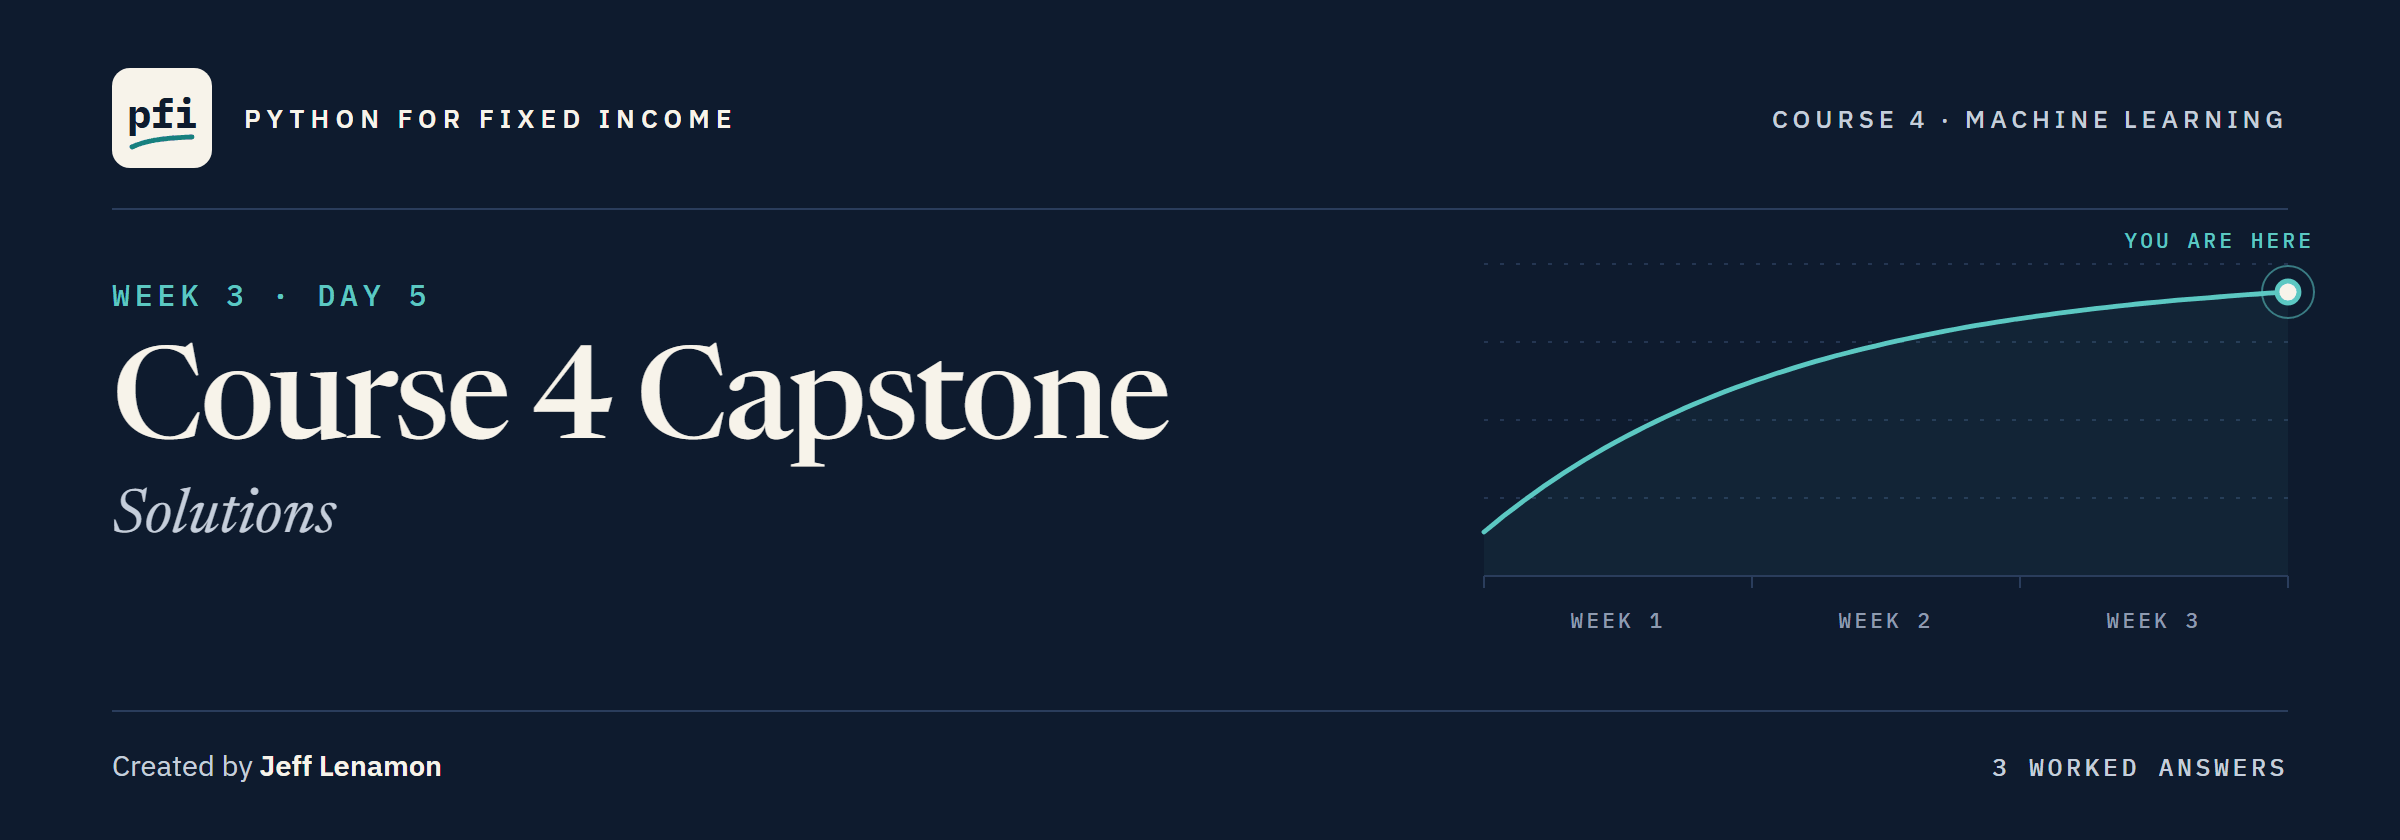

# Course 4 Capstone: Solutions

Week 3, Day 5. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course04_machine_learning/week3/day5/course4_capstone_solutions.ipynb)

# Problem Statement

## Business Context

A colleague who covers emerging market corporates hands you a public file: financial statements of Polish companies, 64 ratios each, and a flag for the companies that went bankrupt within a year.
The dataset page says the bankrupt companies were analysed from 2000 to 2012 and the ones still operating from 2007 to 2013 ([dataset page](https://archive.ics.uci.edu/dataset/365/polish+companies+bankruptcy+data)).
It is one country in one period, and that market differs from US credit.
She asks which of three standard models best separates the companies that went bankrupt, how well on companies it never saw, and where it fails.
A model's output here is "the model's probability of bankruptcy in this file", or "flagged at threshold t", never a credit view on any company.
The work is yours: each question has an empty cell and a `check()` line, and the solutions notebook is one worked answer.

## Objectives

Describe the file's gaps, copies and extremes, and look at it without the label.
Fit a logistic regression and two pruned trees inside pipelines, and choose every setting and a threshold for a recall of 0.70 on folds of the training rows.
Open the test rows once, then describe what the chosen model leans on and where it fails.

![The capstone on one page, in three sittings. Sitting one, the file: loading the data, the data overview, the exploratory analysis, the preparation, and a look without the label. Sitting two, the models: model building, performance improvement, and final model selection, every setting and the threshold for a recall of 0.70 chosen on folds. Sitting three, the verdict: the test rows opened once, where the model fails, and the insights and conclusion. The test rows stay closed through sittings one and two.](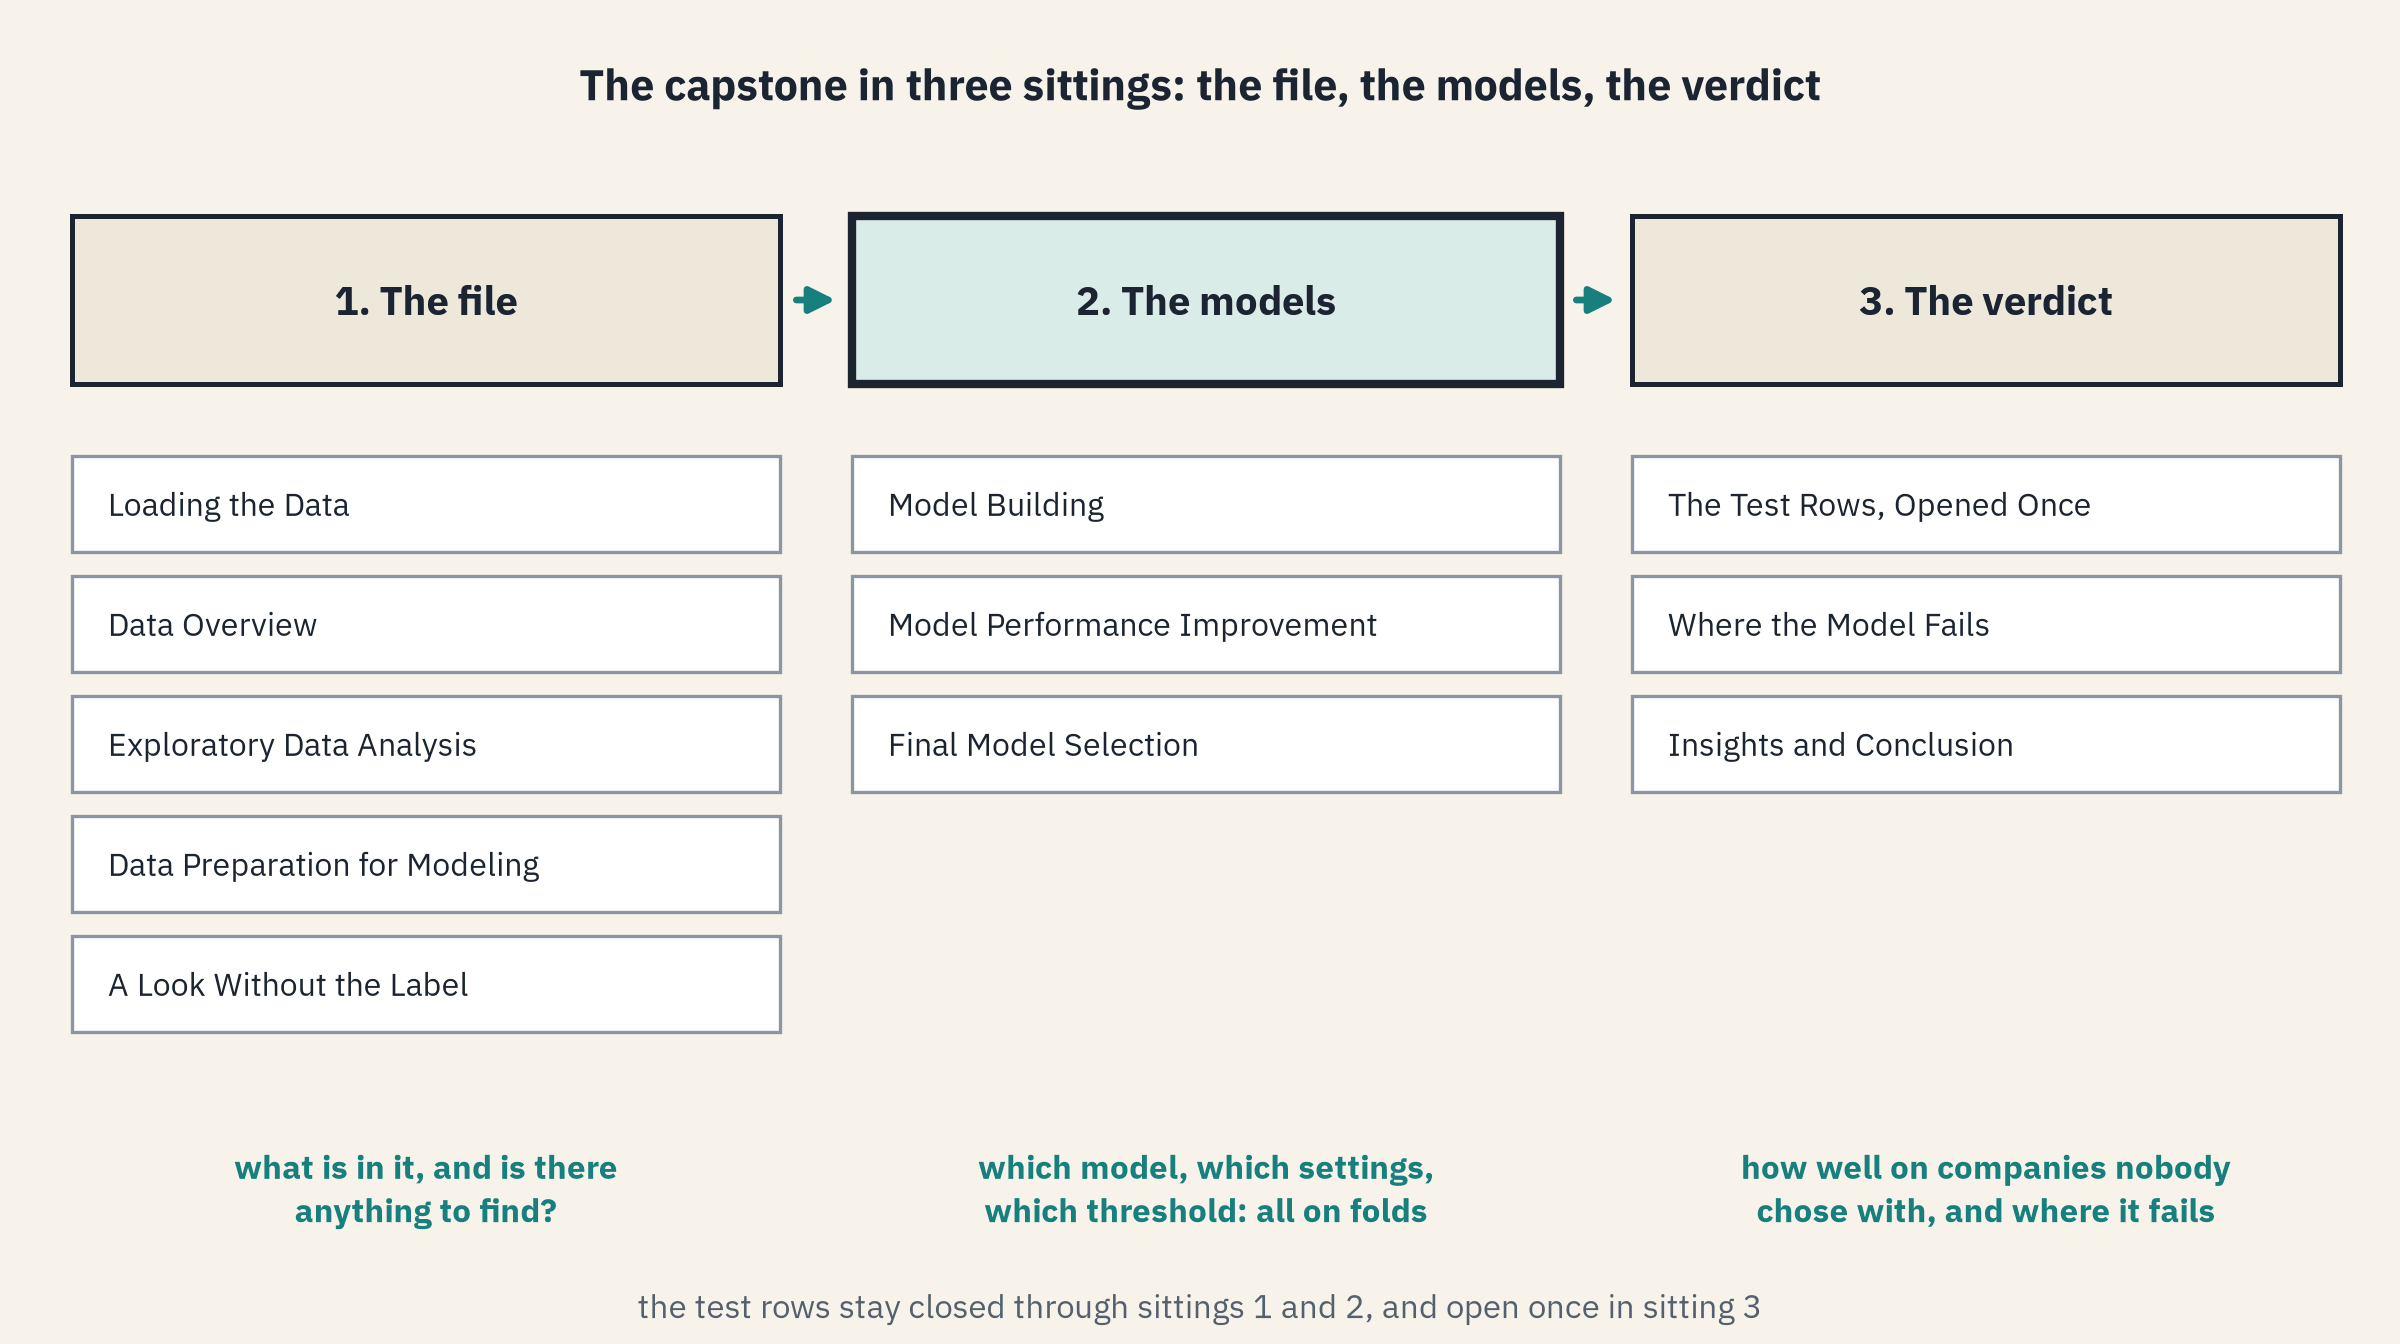)

## Data Dictionary

`polish_bankruptcy_5year.csv`, one row per financial statement:

1. `Attr1` to `Attr64`: the 64 features, the page's X1 to X64 in order (the file proves it below)
2. `class`: 1 if the company went bankrupt within a year, **the target**

The features this notebook names, as the page defines them:

- `Attr2` (X2): total liabilities / total assets
- `Attr17` (X17): total assets / total liabilities
- `Attr21` (X21): sales (n) / sales (n-1)
- `Attr27` (X27): profit on operating activities / financial expenses
- `Attr32` (X32): (current liabilities x 365) / cost of products sold
- `Attr33` (X33): operating expenses / short-term liabilities
- `Attr37` (X37): (current assets - inventories) / long-term liabilities
- `Attr39` (X39): profit on sales / sales
- `Attr60` (X60): sales / inventory
- `Attr63` (X63): sales / short-term liabilities

Most features are ratios; X29 is a logarithm of total assets, X55 is working capital (an amount), and nine, X32 among them, are in days.
The provider kept only statements with `Attr20` present, a filter named in the header of the fifth-year file in the [UCI download](https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip), so `Attr20` never has a gap.

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# to split the rows, fold them, choose settings, and score each row out of fold
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV

# the steps of a pipeline, and the models
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text

# to score flags and rankings
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score, confusion_matrix
from sklearn.metrics import roc_auc_score, precision_recall_curve, average_precision_score

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:,.4f}".format)

# one colour for each of the four kinds of account a confusion matrix counts, the same on Days 7 to 10
CELL_COLOURS = {"TN": "#56B4E9", "FP": "#DE8F05", "FN": "#D55E00", "TP": "#0173B2"}

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is written on the page.
A number is rounded to the places its question asks for, so you need not round it yourself.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

# Loading the Data

## Reading the File

In [4]:
# the 5,910 statements: 64 features named Attr1 to Attr64, and the outcome in class
bankrupt = pd.read_csv(DATA + "polish_bankruptcy_5year.csv")
TARGET = "class"
FEATURES = [column for column in bankrupt.columns if column != TARGET]
print(len(FEATURES), "features")

64 features


## The File Proves Its Own Names

The page's X17 is the reciprocal of its X2, so if the file's names follow the page, `Attr17` x `Attr2` is 1.

5890 of 5891 rows have Attr17 x Attr2 within 1 percent of 1


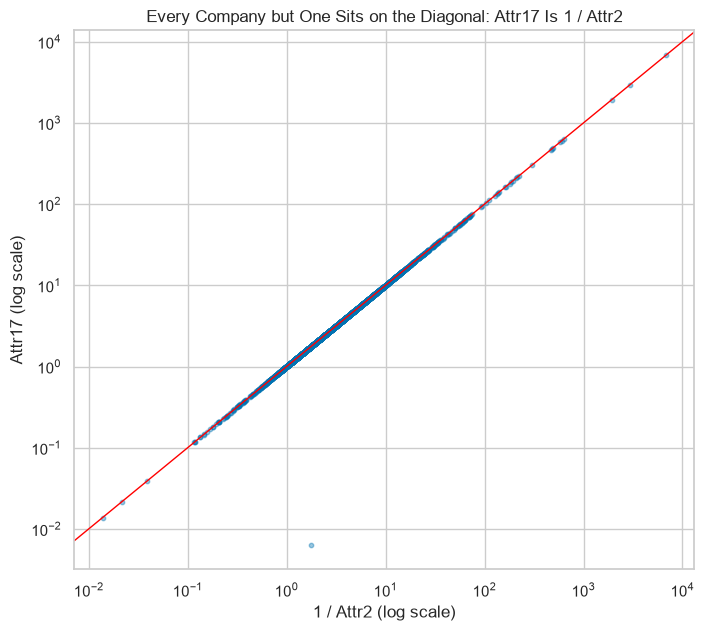

In [5]:
# the rows with both features; if the names follow the page, Attr17 x Attr2 is 1
both = bankrupt[["Attr2", "Attr17"]].dropna()
within = ((both["Attr17"] * both["Attr2"]) - 1).abs() < 0.01
print(within.sum(), "of", len(both), "rows have Attr17 x Attr2 within 1 percent of 1")

# Attr17 against 1 / Attr2 on log axes, the diagonal where the two are equal
plt.figure(figsize=(8, 7))
plt.scatter(1 / both["Attr2"], both["Attr17"], s=10, alpha=0.4)
plt.axline((1, 1), (10, 10), color="red", linewidth=1)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("1 / Attr2 (log scale)")
plt.ylabel("Attr17 (log scale)")
plt.title("Every Company but One Sits on the Diagonal: Attr17 Is 1 / Attr2")
plt.show()

5,890 of 5,891 rows sit on the diagonal, so `Attr`k is read as the page's Xk from here on.

# Data Overview

## Shape, Outcome and Dates

Q. How many rows does the file hold, how many companies went bankrupt, and what share is that in percent? How many columns hold decimal numbers (`float64`)? Store them in `q1_rows`, `q1_bankrupt`, `q1_share` (2 decimals) and `q1_decimal_columns`.

In [6]:
# the rows, the bankrupt companies and their share in percent
q1_rows = len(bankrupt)
q1_bankrupt = bankrupt[TARGET].sum()
q1_share = bankrupt[TARGET].mean() * 100
print(q1_rows, "rows,", q1_bankrupt, "bankrupt,", round(q1_share, 2), "percent")

# the column types
q1_decimal_columns = (bankrupt.dtypes == "float64").sum()
bankrupt.dtypes.value_counts()

5910 rows, 410 bankrupt, 6.94 percent


float64    64
int64       1
Name: count, dtype: int64

410 of 5,910 companies went bankrupt, 6.94 percent: a rare label.

64 decimal columns and one whole-number column, the outcome.

No column holds a date, so the file has no time order: the split below is at random, never walked forward through time.

In [7]:
check("Q1 rows", q1_rows, "e153ee97eb46", places=0)
check("Q1 bankrupt companies", q1_bankrupt, "43ab3e2ff147", places=0)
check("Q1 bankrupt share", q1_share, "6b33f06c8c1e", places=2)
check("Q1 decimal columns", q1_decimal_columns, "12f77c444b55", places=0)

Q1 rows: correct
Q1 bankrupt companies: correct
Q1 bankrupt share: correct
Q1 decimal columns: correct


## Missing Values

Q. How many cells are empty, how many columns and how many rows have at least one gap, and which column has the most? Store them in `q2_cells`, `q2_columns`, `q2_rows` and `q2_worst` (the column's name).

In [8]:
# the empty cells in each column, then the totals
gaps = bankrupt.isnull().sum()
q2_cells = gaps.sum()
q2_columns = (gaps > 0).sum()
q2_rows = bankrupt.isnull().any(axis=1).sum()
q2_worst = gaps.idxmax()
print(q2_cells, "cells,", q2_columns, "columns,", q2_rows, "rows; the most in", q2_worst, gaps.max(), "rows,", round(gaps.max() / len(bankrupt) * 100, 1), "percent")

4666 cells, 49 columns, 2879 rows; the most in Attr37 2548 rows, 43.1 percent


4,666 empty cells, in 49 of the 64 features.

2,879 rows, nearly half the file, have at least one gap, so dropping them would throw half the companies away.

`Attr37` is empty for 2,548 companies, 43.1 percent.

In [9]:
check("Q2 empty cells", q2_cells, "d7584fbce696", places=0)
check("Q2 columns with a gap", q2_columns, "83cef8e1fd3b", places=0)
check("Q2 rows with a gap", q2_rows, "5a62d0639230", places=0)
check("Q2 the column with the most", q2_worst, "632c24c7ea5d")

Q2 empty cells: correct
Q2 columns with a gap: correct
Q2 rows with a gap: correct
Q2 the column with the most: correct


## Where the Gaps Are

In [10]:
# where the bankrupt companies sit in the file, and Attr21's empty cells for each outcome
first_bankrupt = bankrupt.index[bankrupt[TARGET] == 1].min()
print("The bankrupt companies are rows", first_bankrupt, "to", len(bankrupt) - 1, "of the file")
bankrupt["Attr21"].isnull().groupby(bankrupt[TARGET]).sum()

The bankrupt companies are rows 5500 to 5909 of the file


class
0     4
1    99
Name: Attr21, dtype: int64

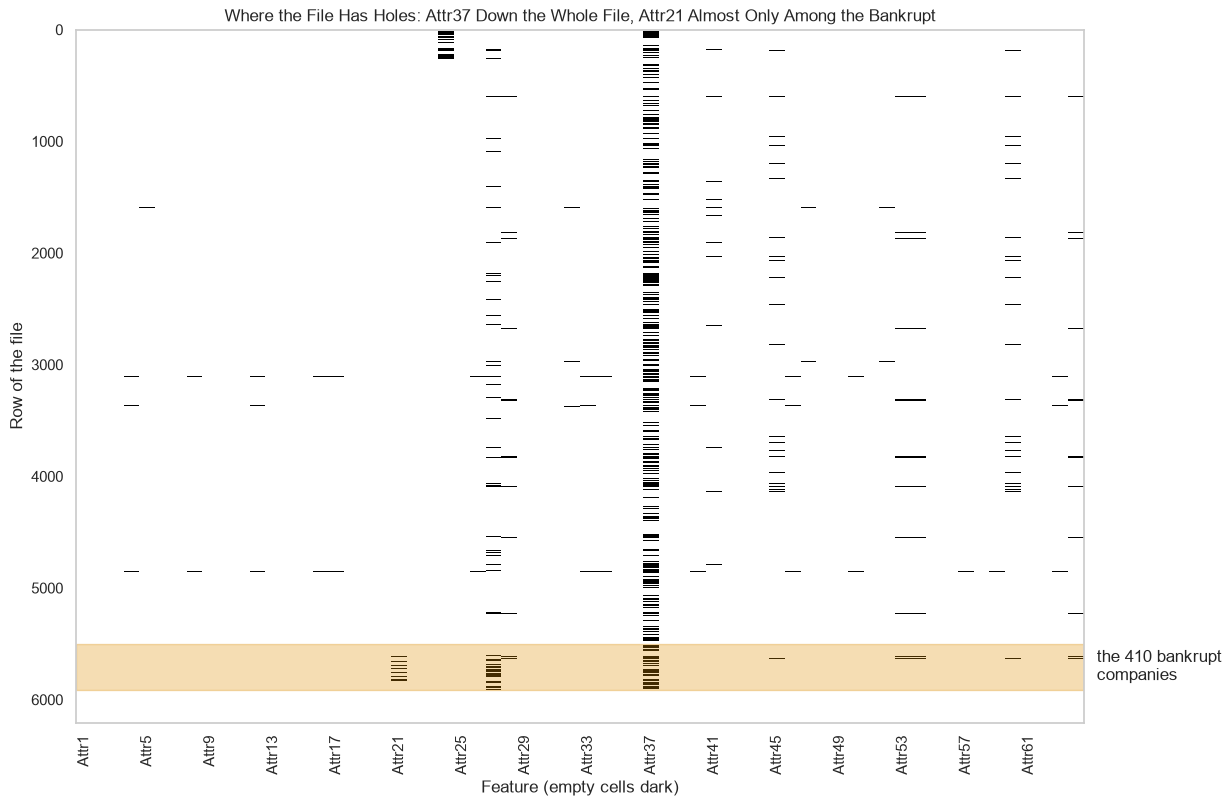

In [11]:
# every empty cell as a dark mark: the 5,910 statements down, the 64 features across
plt.figure(figsize=(13, 9))
plt.imshow(bankrupt[FEATURES].isnull(), aspect="auto", cmap="Greys", interpolation="nearest")
plt.grid(False)

# the bankrupt companies shaded, and every fourth feature named
plt.axhspan(first_bankrupt, len(bankrupt), color="C1", alpha=0.3)
plt.text(64, (first_bankrupt + len(bankrupt)) / 2, " the 410 bankrupt\n companies", va="center", fontsize=12)
plt.xticks(range(0, 64, 4), FEATURES[::4], rotation=90)
plt.xlabel("Feature (empty cells dark)")
plt.ylabel("Row of the file")
plt.title("Where the File Has Holes: Attr37 Down the Whole File, Attr21 Almost Only Among the Bankrupt")
plt.show()

The 410 bankrupt companies are the file's last rows, so a split that kept the file's order would put them all on one side.

`Attr21` (X21, this year's sales over last year's) is empty for 99 bankrupt companies and only 4 others.

**Predict 1**

Q. Among the companies where `Attr37` is empty, what share went bankrupt, in percent? And among those where it is present? Write down two numbers.

## Does a Gap Say Something?

Q. Compute both shares in percent, each with Course 1's rough margin, 1.96 x sqrt(p x (1 - p) / n), and keep them in a table `by_gap`. Store the two shares in `q3_empty` and `q3_present` (2 decimals).

Q. Draw the two shares as dots, each with its margin as a whisker, and the whole file's share as a dashed line.

In [12]:
# the bankrupt share where Attr37 is present (False) and empty (True), with Course 1's rough margin
by_gap = bankrupt.groupby(bankrupt["Attr37"].isnull())[TARGET].agg(["size", "mean"])
by_gap["margin"] = 1.96 * np.sqrt(by_gap["mean"] * (1 - by_gap["mean"]) / by_gap["size"])

# both in percent, the rows named
by_gap[["mean", "margin"]] = by_gap[["mean", "margin"]] * 100
by_gap.index = ["Attr37 present", "Attr37 empty"]
q3_empty, q3_present = by_gap.loc["Attr37 empty", "mean"], by_gap.loc["Attr37 present", "mean"]
by_gap

,size,mean,margin
Attr37 present,3362,5.9488,0.7996
Attr37 empty,2548,8.2418,1.0678


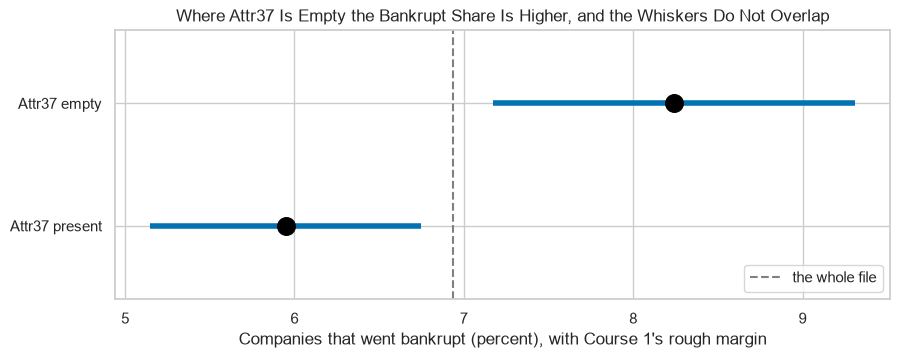

In [13]:
# each share as a dot, its margin as a whisker, the whole file's share dashed
plt.figure(figsize=(10, 3.5))
plt.hlines(by_gap.index, by_gap["mean"] - by_gap["margin"], by_gap["mean"] + by_gap["margin"], linewidth=4)
plt.scatter(by_gap["mean"], by_gap.index, s=160, color="black", zorder=3)
plt.axvline(bankrupt[TARGET].mean() * 100, color="gray", linestyle="--", label="the whole file")
plt.ylim(-0.6, 1.6)
plt.xlabel("Companies that went bankrupt (percent), with Course 1's rough margin")
plt.title("Where Attr37 Is Empty the Bankrupt Share Is Higher, and the Whiskers Do Not Overlap")
plt.legend(loc="lower right")
plt.show()

8.24 percent (plus or minus 1.07) where `Attr37` is empty against 5.95 (plus or minus 0.80) where it is present: the whiskers do not meet.

An empty cell says something about the outcome, and a median filled into it alone would hide that.

**So the preparation will keep the gap itself as a column of its own.**

In [14]:
check("Q3 share where empty", q3_empty, "acd4a4732702", places=2)
check("Q3 share where present", q3_present, "4268f770652c", places=2)

Q3 share where empty: correct
Q3 share where present: correct


## Copies

Q. How many rows repeat an earlier row exactly, how many of the rows with a twin are bankrupt, and how many rows repeat the 64 features but not the outcome? Store them in `q4_copies`, `q4_bankrupt` and `q4_conflicts`.

In [15]:
# rows that repeat an earlier row, and every row that has a twin
q4_copies = bankrupt.duplicated().sum()
twins = bankrupt[bankrupt.duplicated(keep=False)]
q4_bankrupt = twins[TARGET].sum()

# rows that repeat the features alone, less the rows that repeat everything
q4_conflicts = bankrupt[FEATURES].duplicated().sum() - q4_copies
print(q4_copies, "copies,", len(twins), "rows with a twin,", q4_bankrupt, "of them bankrupt,", q4_conflicts, "conflicts")

60 copies, 120 rows with a twin, 4 of them bankrupt, 0 conflicts


60 rows repeat an earlier one exactly, 120 rows in all have a twin, 4 of them bankrupt, and no two twins disagree on the outcome.

Left in, a copy could land on both sides of the split, and the model would be scored on a row it learned from.

In [16]:
check("Q4 copies", q4_copies, "9be8b4e0c00a", places=0)
check("Q4 bankrupt rows with a twin", q4_bankrupt, "31b5c3a27d3c", places=0)
check("Q4 conflicts", q4_conflicts, "f339131491ad", places=0)

Q4 copies: correct
Q4 bankrupt rows with a twin: correct
Q4 conflicts: correct


## Extremes

Q. Which feature holds the largest value in the file, and what is it? How many features reach above a million? Store them in `q5_column`, `q5_max` (0 decimals) and `q5_over_million`.

In [17]:
# each feature's largest value, the largest of all, and the features above a million
largest = bankrupt[FEATURES].max()
q5_column, q5_max = largest.idxmax(), largest.max()
q5_over_million = (largest > 1e6).sum()
print(q5_column, q5_max, " its 99th percentile:", round(bankrupt[q5_column].quantile(0.99), 1), " features above a million:", q5_over_million)

Attr60 4818700.0  its 99th percentile: 686.7  features above a million: 5


`Attr60` (X60, sales / inventory) reaches 4,818,700, while 99 percent of companies sit at or below 686.7: a ratio over an inventory of almost nothing.

Five features reach above a million.

In [18]:
check("Q5 column", q5_column, "b0e16315352e")
check("Q5 largest value", q5_max, "826d592ded6e", places=0)
check("Q5 features above a million", q5_over_million, "bab51638fe9e", places=0)

Q5 column: correct
Q5 largest value: correct
Q5 features above a million: correct


## How Far Every Feature Reaches

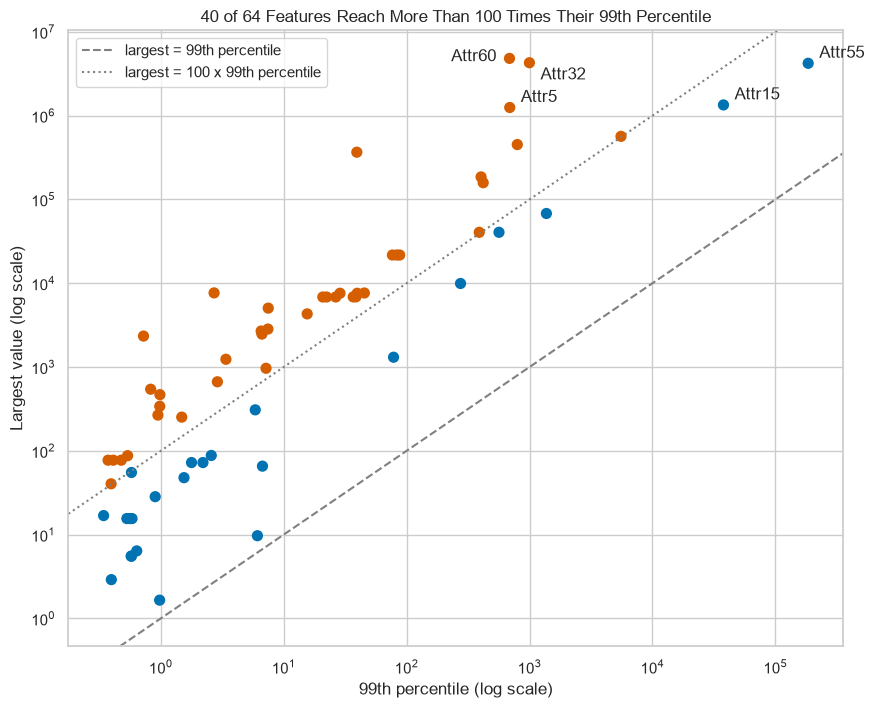

In [19]:
# each feature's largest value against its 99th percentile, log axes; red if the largest is more than 100 times it
reach = pd.DataFrame({"p99": bankrupt[FEATURES].quantile(0.99), "largest": bankrupt[FEATURES].max()})
far = reach["largest"] > 100 * reach["p99"]
plt.figure(figsize=(10, 8))
plt.scatter(reach["p99"], reach["largest"], c=far.map({True: "C3", False: "C0"}), s=50)
for name, shift in zip(reach["largest"].nlargest(5).index, [(-42, -2), (8, -12), (8, 4), (8, 4), (8, 4)]):
    plt.annotate(name, (reach.loc[name, "p99"], reach.loc[name, "largest"]), xytext=shift, textcoords="offset points")
plt.axline((1, 1), (10, 10), color="gray", linestyle="--", label="largest = 99th percentile")
plt.axline((1, 100), (10, 1000), color="gray", linestyle=":", label="largest = 100 x 99th percentile")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("99th percentile (log scale)")
plt.ylabel("Largest value (log scale)")
plt.title(f"{far.sum()} of 64 Features Reach More Than 100 Times Their 99th Percentile")
plt.legend(loc="upper left")
plt.show()

40 of the 64 features reach more than 100 times their 99th percentile.

A ratio with a denominator near zero can be enormous with nothing wrong in its arithmetic.

**The preparation needs three things: the gaps kept as columns, the copies dropped, and Day 10's quantile transform for the extremes.**

# Exploratory Data Analysis

## Profit on Sales by Outcome

Q. What is the median `Attr39` (X39, profit on sales / sales) of the companies that went bankrupt, and of those that did not? Store them in `q6_bankrupt` and `q6_survived` (4 decimals).

A **raincloud plot** stacks three views of one distribution: a half violin (the cloud), a narrow box under it, and every row as a dot (the rain).

Q. Draw a raincloud of `Attr39` for each outcome, for the companies between its 1st and 99th percentiles, the dots shifted a little with `np.random.default_rng(SEED)`.
`sns.violinplot(split=True)` with no `hue` draws half a violin, and `native_scale=True` places it at the outcome's own number, 0 or 1.

In [20]:
# the median profit on sales over sales, for each outcome
medians = bankrupt.groupby(TARGET)["Attr39"].median()
q6_survived, q6_bankrupt = medians[0], medians[1]
medians

class
0    0.0433
1   -0.0502
Name: Attr39, dtype: float64

In [21]:
# the companies between the 1st and 99th percentiles of Attr39, each outcome in words
low, high = bankrupt["Attr39"].quantile([0.01, 0.99])
inside = bankrupt[bankrupt["Attr39"].between(low, high)].copy()
inside["outcome"] = inside[TARGET].map({0: "did not go bankrupt", 1: "went bankrupt"})

# each company's place in the rain: just under its outcome's cloud, shifted a little at random with the seed
inside["rain"] = inside[TARGET] + 0.42 + np.random.default_rng(SEED).uniform(-0.05, 0.05, len(inside))
print(len(inside), "of", len(bankrupt), "companies kept, from", round(low, 4), "to", round(high, 4))

5790 of 5910 companies kept, from -0.7524 to 0.3956


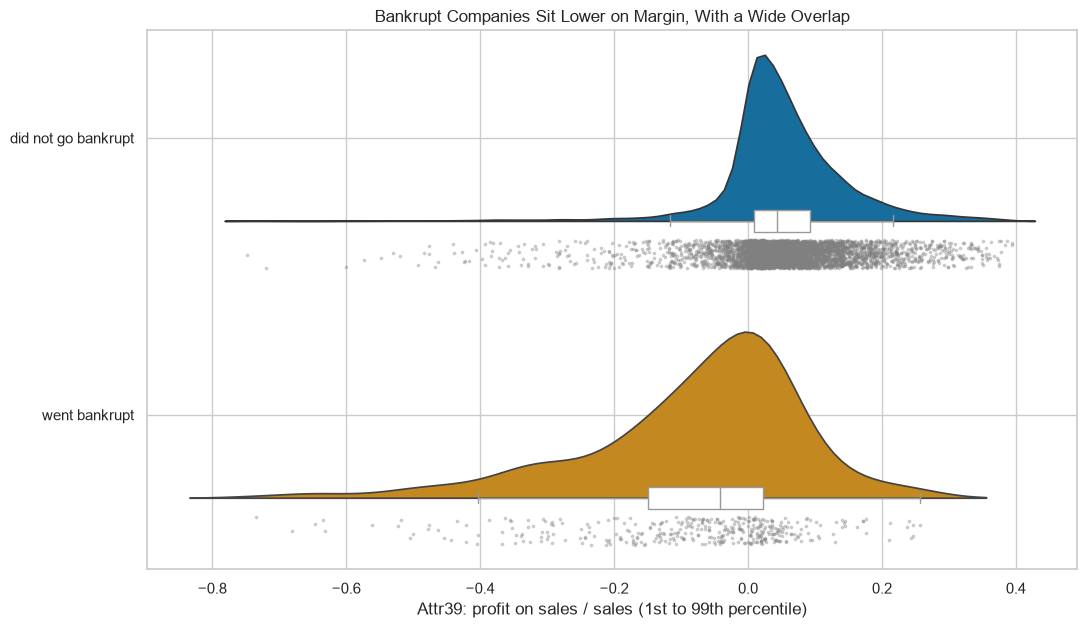

In [22]:
# the clouds: half a violin for each outcome, at y = 0 and y = 1
plt.figure(figsize=(12, 7))
for outcome, colour in [(0, "C0"), (1, "C1")]:
    rows = inside[inside[TARGET] == outcome]
    sns.violinplot(x=rows["Attr39"], y=rows[TARGET], orient="h", native_scale=True, split=True, inner=None, color=colour, width=0.6)

# a narrow box along each cloud's flat side, then the rain under it
sns.boxplot(x=inside["Attr39"], y=inside[TARGET] + 0.3, orient="h", native_scale=True, width=0.08, showfliers=False, color="white")
plt.scatter(inside["Attr39"], inside["rain"], s=3, alpha=0.3, color="gray")
plt.gca().invert_yaxis()
plt.yticks([0, 1], ["did not go bankrupt", "went bankrupt"])
plt.xlabel("Attr39: profit on sales / sales (1st to 99th percentile)")
plt.ylabel("")
plt.title("Bankrupt Companies Sit Lower on Margin, With a Wide Overlap")
plt.show()

The medians are 0.0433 for the companies that did not go bankrupt and -0.0502 for those that did.

The two clouds overlap across most of their range.

**One ratio will not separate the outcomes, so the models get all 64.**

In [23]:
check("Q6 median, bankrupt", q6_bankrupt, "e50f63823885", places=4)
check("Q6 median, did not go bankrupt", q6_survived, "ab55130ee23c", places=4)

Q6 median, bankrupt: correct
Q6 median, did not go bankrupt: correct


# Data Preparation for Modeling

## Copies Out, Then One Split

Q. Drop the exact copies, then split the rest 80/20 into `X_train, X_test, y_train, y_test` with `stratify=y` and the course seed. Store the number of training rows in `q7_train_rows` and of test bankruptcies in `q7_test_bankrupt`.

In [24]:
# the copies out first, then one stratified split
unique = bankrupt.drop_duplicates()
X, y = unique[FEATURES], unique[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
q7_train_rows, q7_test_bankrupt = len(X_train), y_test.sum()
print(len(unique), "rows,", y.sum(), "bankrupt")
print("Training:", len(X_train), "rows,", y_train.sum(), "bankrupt.  Test:", len(X_test), "rows,", q7_test_bankrupt, "bankrupt")

5850 rows, 408 bankrupt
Training: 4680 rows, 326 bankrupt.  Test: 1170 rows, 82 bankrupt


In [25]:
check("Q7 training rows", q7_train_rows, "e406c5a57ef9", places=0)
check("Q7 test bankruptcies", q7_test_bankrupt, "b809cf3f69ed", places=0)

Q7 training rows: correct
Q7 test bankruptcies: correct


![The rows' roles. 5,910 statements; 60 exact copies dropped leaves 5,850, 408 of them bankrupt. One stratified split, with the course seed: 4,680 training rows, 326 bankrupt, cut into five folds of 936 that fit, score and choose every setting and the threshold; and 1,170 test rows, 82 bankrupt, closed until one model is chosen, then opened once.](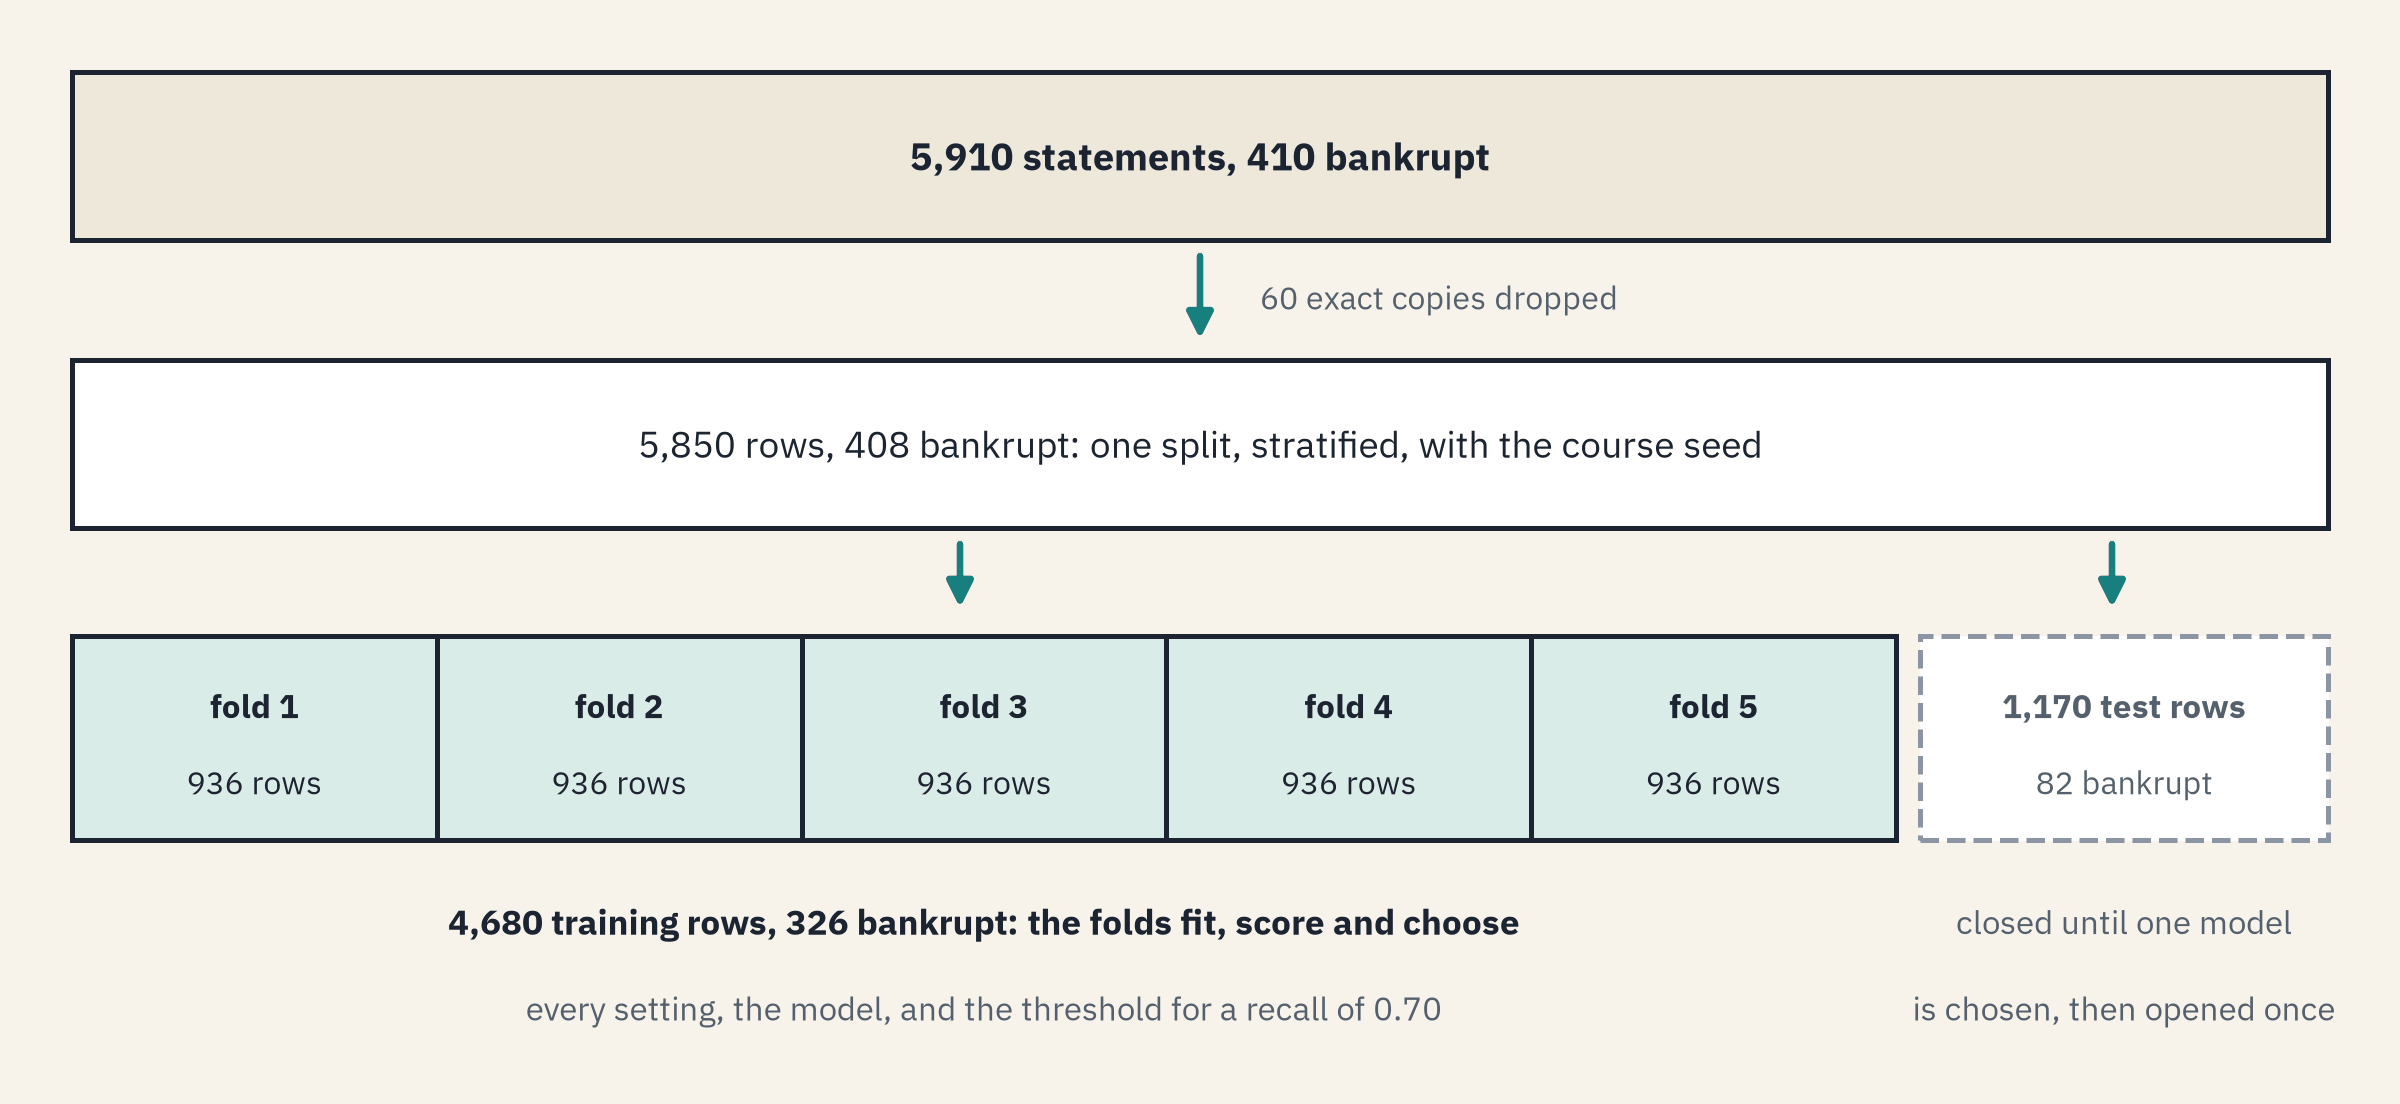)

**Every choice from here is made on the 4,680 training rows; the 1,170 test rows stay closed until one model is chosen.**

# A Look Without the Label

PCA and K-means never see the outcome.
Fitted on the training rows only, they show whether the features alone sort the companies.

**Predict 2**

Q. PCA turns the 64 features into 64 directions, largest first. How many directions does it take to reach 80 percent of the variance? Write down a number.

## Many Features, Few Directions

The quantile transform puts every feature on one scale, normal scores, so no feature's extremes take over a direction.

`SimpleImputer(strategy="median")` fills each gap with its column's median, learned at `fit` from the rows it is given.

Q. Fit a pipeline of that imputer, Day 10's quantile transform and Day 14's `PCA(random_state=SEED)` on `X_train` (steps `"impute"`, `"quantile"`, `"pca"`), keeping its output as `train_scores`. Store the first component's share of the variance in percent in `q8_first` (2 decimals) and the components that reach 80 percent in `q8_components`.

Q. Draw Day 14's scree plot of the first 20 components: each one's share as a bar, the running total as a line, and 80 percent dashed.

In [26]:
# the gaps filled, every feature given its normal score, then PCA: all fitted on the training rows only
pca_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("pca", PCA(random_state=SEED))])
train_scores = pca_pipe.fit_transform(X_train)

# each component's share of the variance in percent, and the running total
shares = pca_pipe["pca"].explained_variance_ratio_ * 100
running = shares.cumsum()
q8_first, q8_components = shares[0], (running < 80).sum() + 1
print(round(q8_first, 2), "percent on the first;", q8_components, "components reach 80 percent,", (running < 90).sum() + 1, "reach 90")

38.95 percent on the first; 8 components reach 80 percent, 15 reach 90


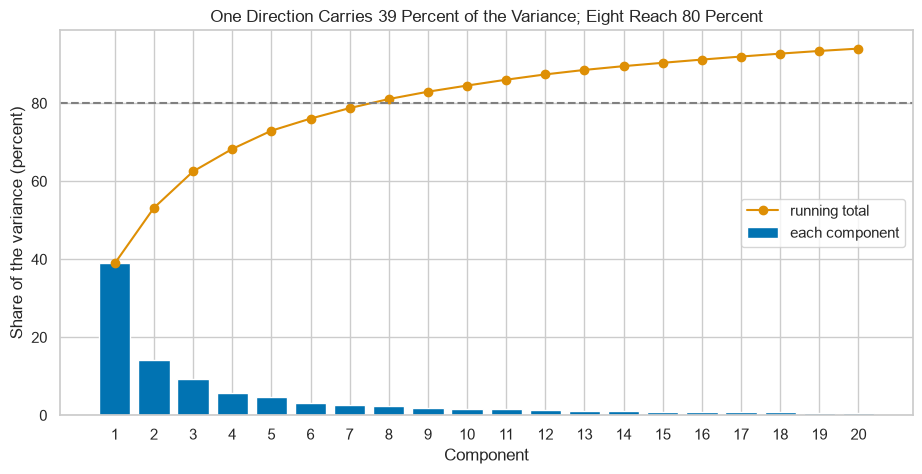

In [27]:
# the first 20 components: each one's share as a bar, the running total as a line, 80 percent dashed
plt.figure(figsize=(11, 5))
plt.bar(range(1, 21), shares[:20], label="each component")
plt.plot(range(1, 21), running[:20], marker="o", color="C1", label="running total")
plt.axhline(80, color="gray", linestyle="--")
plt.xticks(range(1, 21))
plt.xlabel("Component")
plt.ylabel("Share of the variance (percent)")
plt.title("One Direction Carries 39 Percent of the Variance; Eight Reach 80 Percent")
plt.legend(loc="center right")
plt.show()

The first component carries 38.95 percent of the variance, and 8 of 64 reach 80 percent (15 reach 90).

Many of the features are built from the same few accounts, so they move together.

In [28]:
check("Q8 first component", q8_first, "e9dd83ed54ab", places=2)
check("Q8 components for 80 percent", q8_components, "bcc20ea213a8", places=0)

Q8 first component: correct
Q8 components for 80 percent: correct


## Four Clusters on Two Components

Q. Run Day 12's `KMeans(n_clusters=4, n_init=10, random_state=SEED)` on the first two columns of `train_scores`, numbering the clusters by size, largest 0, as Day 12 does. Give each cluster's size, bankruptcies and bankrupt share in percent in a table `profile`. Store the highest share in `q9_top_share` (2 decimals) and that cluster's bankruptcies in `q9_top_count`.

Q. Draw the training companies on the two components with each cluster's area shaded (Day 12's nearest-centre tiles: `contourf` over a grid, each point given its cluster by `kmeans.predict`), the bankrupt companies dark, and each area's size and bankrupt share in the key.

In [29]:
# K-means on the first two components: no outcome goes in
kmeans = KMeans(n_clusters=4, n_init=10, random_state=SEED).fit(train_scores[:, :2])

# the clusters numbered by size, largest first, so the numbers do not depend on the order K-means found them in
by_size = pd.Series(kmeans.labels_).value_counts().index
renumber = {old: new for new, old in enumerate(by_size)}
clusters = pd.Series(kmeans.labels_).map(renumber).to_numpy()

In [30]:
# each cluster's companies, bankruptcies and bankrupt share in percent
profile = pd.DataFrame({"cluster": clusters, "bankrupt": y_train.to_numpy()}).groupby("cluster")["bankrupt"].agg(["size", "sum", "mean"])
profile["mean"] = profile["mean"] * 100
q9_top_share, q9_top_count = profile["mean"].max(), profile.loc[profile["mean"].idxmax(), "sum"]
profile

,size,sum,mean
cluster,,,
0,1695,68,4.0118
1,1292,23,1.7802
2,868,53,6.1060
3,825,182,22.0606


In [31]:
# a fine grid over the two components; each point takes the cluster of its nearest centre
pc1, pc2 = np.meshgrid(np.linspace(-22, 19, 400), np.linspace(-19, 16, 400))
grid = pd.DataFrame({"pc1": pc1.ravel(), "pc2": pc2.ravel()}).to_numpy()
grid_cluster = pd.Series(kmeans.predict(grid)).map(renumber).to_numpy().reshape(pc1.shape)
went = (y_train == 1).to_numpy()
colours = ["C0", "C2", "C4", "C1"]

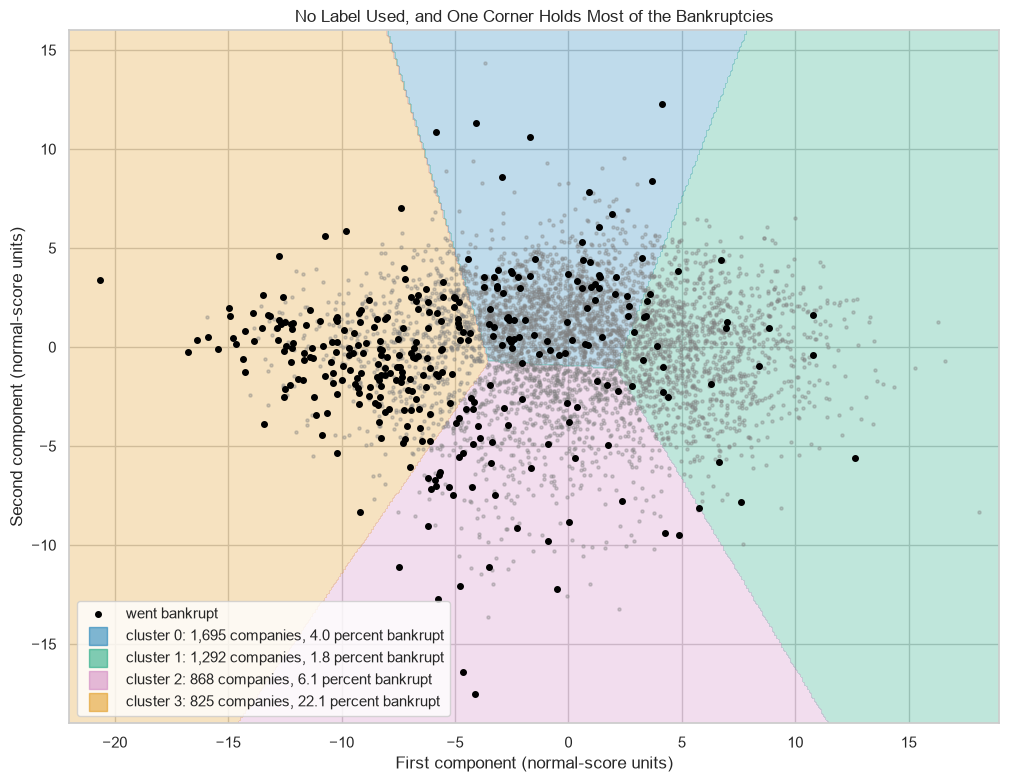

In [32]:
# the four areas shaded, the companies that did not go bankrupt faint, the bankrupt ones dark
plt.figure(figsize=(12, 9))
plt.contourf(pc1, pc2, grid_cluster, levels=[-0.5, 0.5, 1.5, 2.5, 3.5], colors=colours, alpha=0.25)
plt.scatter(train_scores[~went, 0], train_scores[~went, 1], s=5, color="gray", alpha=0.35)
plt.scatter(train_scores[went, 0], train_scores[went, 1], s=16, color="black", label="went bankrupt")

# a key entry for each area (an empty scatter in its colour): its companies and its bankrupt share
for cluster, row in profile.iterrows():
    plt.scatter([], [], marker="s", s=150, color=colours[cluster], alpha=0.5, label=f"cluster {cluster}: {row['size']:,.0f} companies, {row['mean']:.1f} percent bankrupt")
plt.xlabel("First component (normal-score units)")
plt.ylabel("Second component (normal-score units)")
plt.title("No Label Used, and One Corner Holds Most of the Bankruptcies")
plt.legend(loc="lower left")
plt.show()

Cluster 3, the smallest, holds 825 of the 4,680 training companies and 182 of the 326 bankruptcies: 22.1 percent of its companies went bankrupt, against 1.8 to 6.1 percent elsewhere.

The clusters describe the training companies; they rank nothing and score nobody.

**No label went in, and one corner holds most of the bankruptcies: the features carry the outcome, so a model has something to find.**

In [33]:
check("Q9 highest bankrupt share", q9_top_share, "302e9cfc9b18", places=2)
check("Q9 bankruptcies in that cluster", q9_top_count, "4e9a90a6fddd", places=0)

Q9 highest bankrupt share: correct
Q9 bankruptcies in that cluster: correct


# Model Building

## Model Evaluation Criterion

A missed bankruptcy and a flagged survivor are both errors (Day 7), with no money attached here.

About 7 percent went bankrupt, so a model that flags nobody is right 93 percent of the time.

With so rare a label ROC AUC can stay high while the top of the ranking is crowded with survivors, so models are ranked by **average precision** (Day 8) on five folds of the training rows.

Each model then gets a threshold for a recall of 0.70, the desk's illustration.

## The Scoring Function

Day 8's scoring function with average precision added first: the label is rare, so the score that reads the top of the ranking leads.

In [34]:
# flag at or above the threshold, then average precision, ROC AUC and four measures in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "Average precision": [average_precision_score(target, model.predict_proba(predictors)[:, 1])],
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

## Two Pipelines, One Imputer

With `add_indicator=True` the median imputer also adds a 0/1 **missing indicator** column for each feature with a gap in the rows it was fitted on.
All three models start with it.

![Two pipelines that start the same way. The 64 features go into SimpleImputer with strategy median and add_indicator True, which fills each gap with its column's median and adds a 0 or 1 column marking every gap, 112 columns in all. One pipeline then gives every column its normal score with QuantileTransformer and fits a balanced logistic regression; the other fits a balanced decision tree, then pruned, since a tree needs no transform. In cross-validation each step learns from the four folds that fit, never from the fold it is scored on.](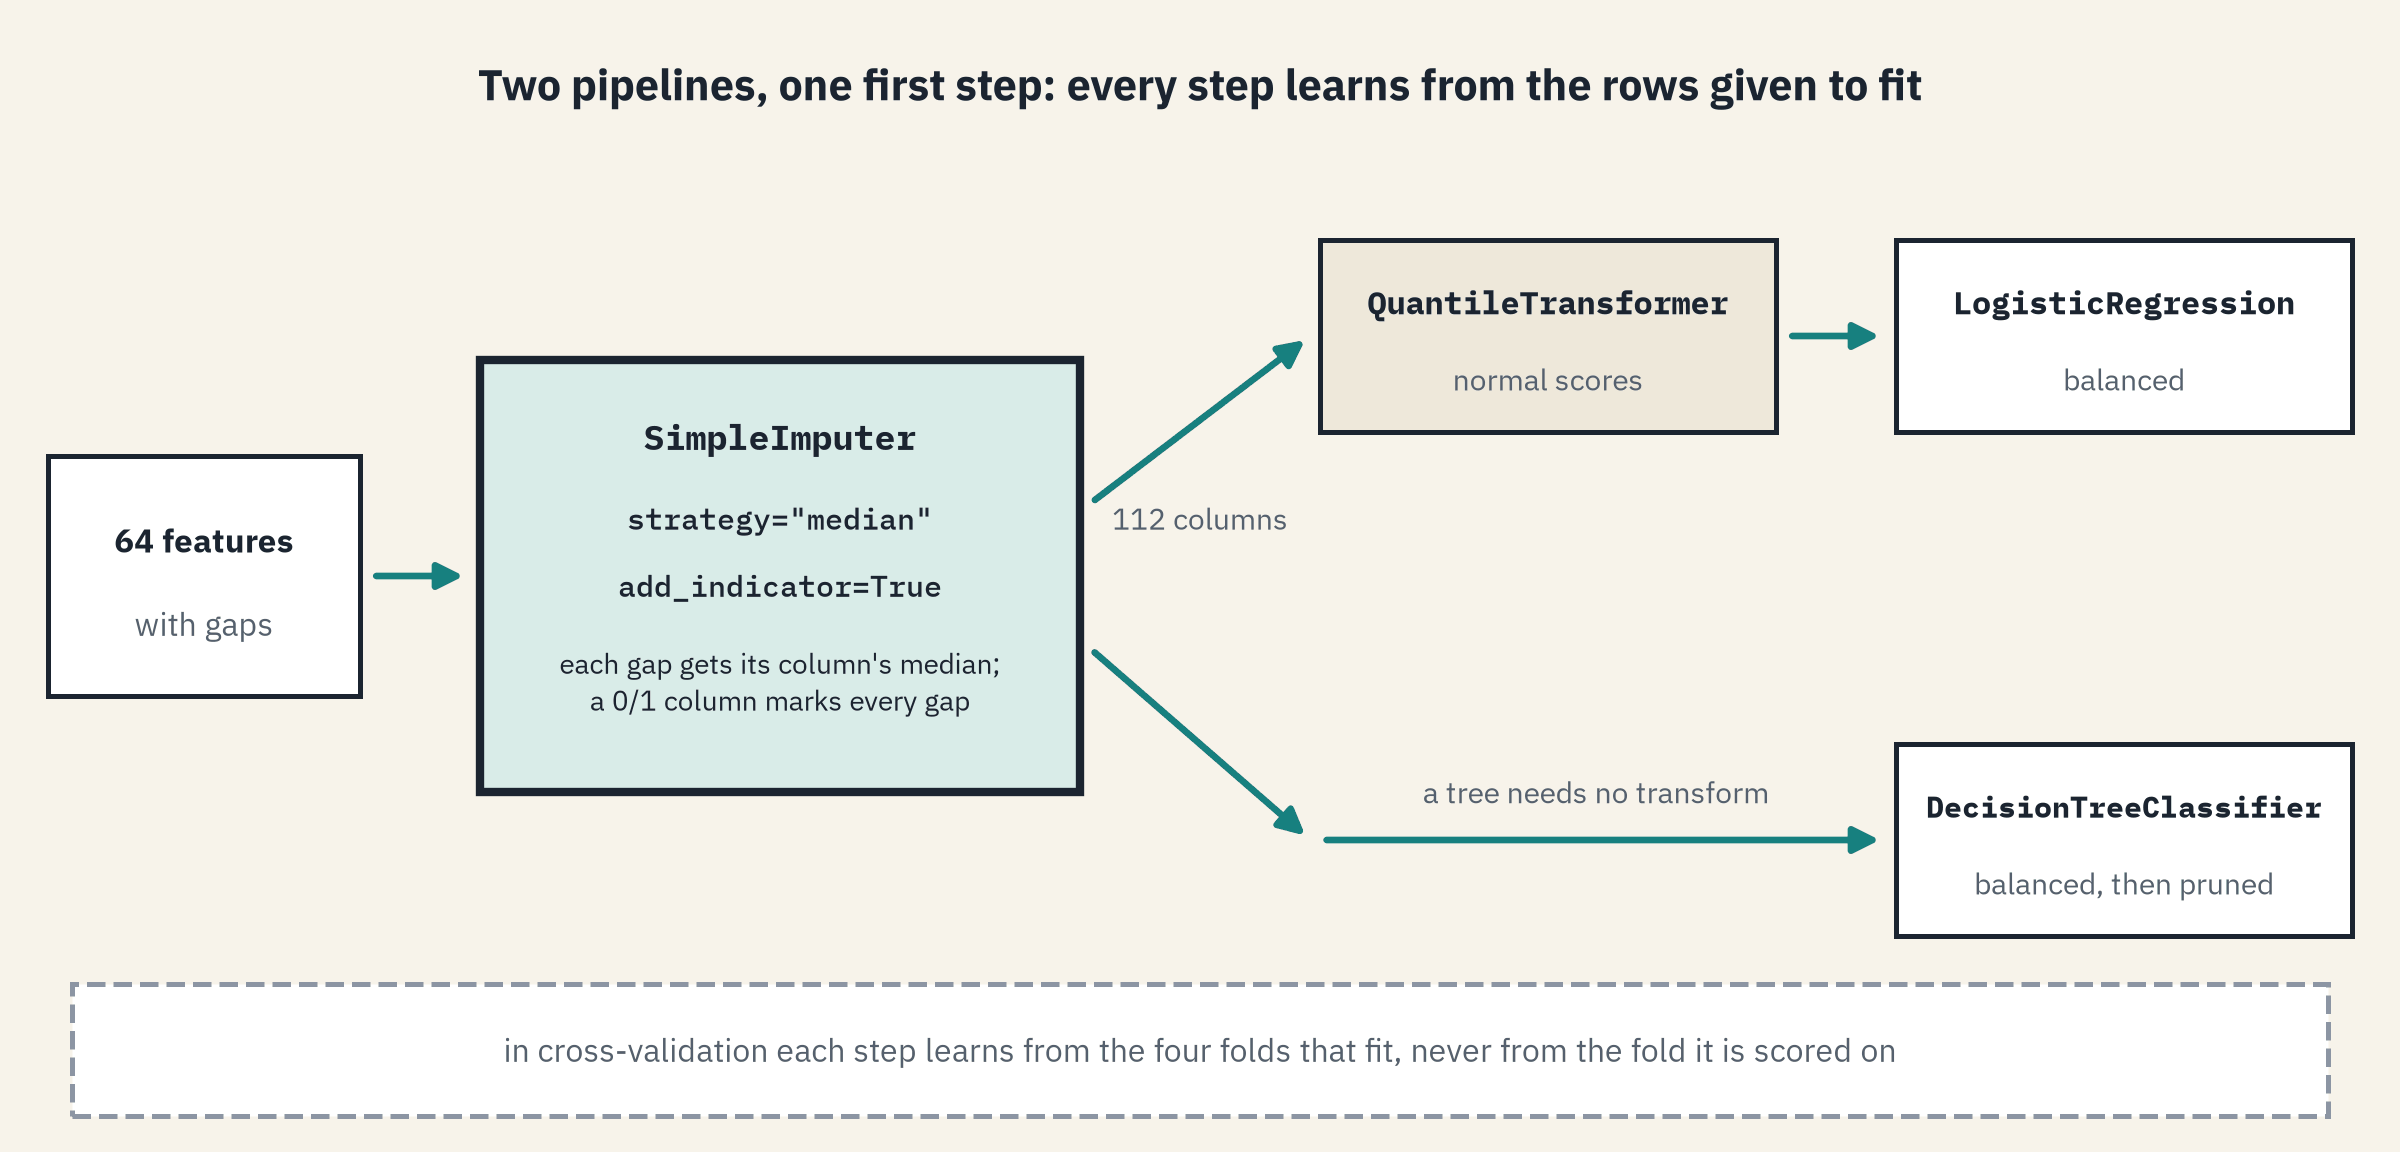)

## Logistic Regression

`solver="newton-cholesky"` with `tol=1e-8` fits the logistic regression to the same coefficients on every machine; the default solver stops short on 112 related columns.

Q. Build `logistic`, a pipeline of that imputer, Day 10's quantile transform and `LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced")` (steps `"impute"`, `"quantile"`, `"logit"`). Score it with Day 5's `cross_validate` on Day 9's stratified folds, `folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)`, scoring `["average_precision", "roc_auc"]`: the fold scores come back under `"test_average_precision"` and `"test_roc_auc"`. Store the mean scores in `q10_ap` and `q10_auc` (4 decimals).

In [35]:
# the imputer with missing indicators, the quantile transform, then the logistic regression
logistic = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])

# five stratified folds of the training rows, each scored two ways
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
logistic_cv = cross_validate(logistic, X_train, y_train, cv=folds, scoring=["average_precision", "roc_auc"])
q10_ap, q10_auc = logistic_cv["test_average_precision"].mean(), logistic_cv["test_roc_auc"].mean()
print("Average precision:", round(q10_ap, 4), " ROC AUC:", round(q10_auc, 4))

Average precision: 0.6624  ROC AUC: 0.9281


Average precision 0.6624 and ROC AUC 0.9281 on companies each fold never saw.

A ranking in random order would score about 0.07 in average precision, the bankrupt share.

**A model that ranks companies it never saw, on the first try.**

In [36]:
check("Q10 fold average precision", q10_ap, "225adef27f00", places=4)
check("Q10 fold ROC AUC", q10_auc, "c47217f103c7", places=4)

Q10 fold average precision: correct
Q10 fold ROC AUC: correct


**Predict 3**

Q. Drop the missing indicators and keep everything else. Write down the fold average precision, against 0.6624 with them.

## What the Indicators Are Worth

Q. Score the same pipeline with `add_indicator=False` on the same folds. Store its mean average precision in `q11_ap` (4 decimals).

In [37]:
# the same pipeline without the missing indicators
no_indicators = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=False)),
                          ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                          ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])
no_indicators_cv = cross_validate(no_indicators, X_train, y_train, cv=folds, scoring=["average_precision", "roc_auc"])
q11_ap = no_indicators_cv["test_average_precision"].mean()
print("Average precision:", round(q11_ap, 4), " ROC AUC:", round(no_indicators_cv["test_roc_auc"].mean(), 4))

Average precision: 0.4477  ROC AUC: 0.884


Without the indicators average precision falls from 0.6624 to 0.4477 and ROC AUC from 0.9281 to 0.8840.

**The gaps found in the overview are worth about a third of the average precision, so the indicators stay in every model.**

In [38]:
check("Q11 fold average precision without indicators", q11_ap, "3b344da74d95", places=4)

Q11 fold average precision without indicators: correct


## A Default Tree

Q. Build `tree`, a pipeline of the same imputer and `DecisionTreeClassifier(class_weight="balanced", random_state=SEED)` (steps `"impute"`, `"tree"`). Fit it on the training rows and cross-validate it. Store its leaves in `q12_leaves` and its fold average precision in `q12_ap` (4 decimals).

In [39]:
# the same imputer, then a balanced tree with no limits
tree = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                 ("tree", DecisionTreeClassifier(class_weight="balanced", random_state=SEED))])
tree.fit(X_train, y_train)
tree_cv = cross_validate(tree, X_train, y_train, cv=folds, scoring=["average_precision", "roc_auc"])
q12_leaves, q12_ap = tree["tree"].get_n_leaves(), tree_cv["test_average_precision"].mean()
print("Depth:", tree["tree"].get_depth(), " Leaves:", q12_leaves)
print("Average precision on the training rows:", average_precision_score(y_train, tree.predict_proba(X_train)[:, 1]), " on the folds:", round(q12_ap, 4))

Depth: 39  Leaves: 186
Average precision on the training rows: 1.0  on the folds: 0.2663


39 questions deep with 186 leaves: a perfect 1.0 on the rows it was fitted on and 0.2663 on the folds, Day 9's memoriser again.

In [40]:
check("Q12 leaves", q12_leaves, "820f96e15ea0", places=0)
check("Q12 fold average precision", q12_ap, "b77f18744ae6", places=4)

Q12 leaves: correct
Q12 fold average precision: correct


**The tree is pruned next, two ways, each chosen on the folds.**

# Model Performance Improvement

## Pre-Pruning

In a grid for a pipeline, a step's setting is named with the step, two underscores and the setting: `tree__max_depth`.

Q. Search `max_depth` 4, 6, 8, 10 and `min_samples_leaf` 10, 20, 40 for `tree` with Day 9's `GridSearchCV` on `folds`, scoring `"average_precision"`, as `pre_search`. Keep the best pipeline as `pre_pruned`. Store its depth, its smallest leaf and its fold score in `q13_depth`, `q13_leaf` and `q13_ap` (4 decimals).

Q. Draw the twelve fold scores as an annotated heatmap, depth down and leaf size across, with the best cell outlined.

In [41]:
# twelve settings, each scored on the five folds; the best is refitted on every training row
pre_search = GridSearchCV(tree, {"tree__max_depth": [4, 6, 8, 10], "tree__min_samples_leaf": [10, 20, 40]},
                          cv=folds, scoring="average_precision")
pre_search.fit(X_train, y_train)
pre_pruned = pre_search.best_estimator_
q13_depth, q13_leaf = pre_search.best_params_["tree__max_depth"], pre_search.best_params_["tree__min_samples_leaf"]
q13_ap = pre_search.best_score_
print(pre_search.best_params_, " Fold average precision:", round(q13_ap, 4), " Leaves:", pre_pruned["tree"].get_n_leaves())

{'tree__max_depth': 8, 'tree__min_samples_leaf': 10}  Fold average precision: 0.5254  Leaves: 52


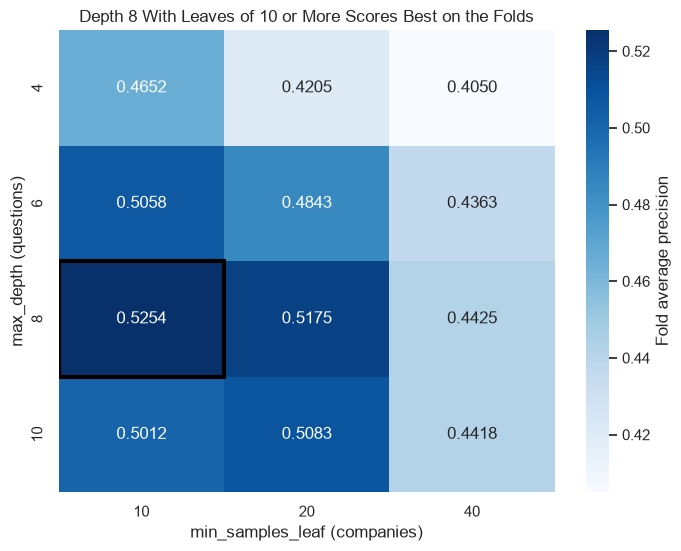

In [42]:
# the twelve fold scores as a table: depth down, smallest leaf across
results = pd.DataFrame(pre_search.cv_results_["params"])
results["score"] = pre_search.cv_results_["mean_test_score"]
table = results.pivot(index="tree__max_depth", columns="tree__min_samples_leaf", values="score")

# the heatmap, the best cell outlined (depth 8 is the third row, leaf 10 the first column)
plt.figure(figsize=(8, 6))
ax = sns.heatmap(table, annot=True, fmt=".4f", cmap="Blues", cbar_kws={"label": "Fold average precision"})
ax.add_patch(plt.Rectangle((0, 2), 1, 1, fill=False, edgecolor="black", linewidth=3))
ax.set(xlabel="min_samples_leaf (companies)", ylabel="max_depth (questions)", title="Depth 8 With Leaves of 10 or More Scores Best on the Folds")
plt.show()

Depth 8 with leaves of at least 10 companies scores 0.5254, with 52 leaves; the largest leaves, 40 companies, score lowest at every depth.

In [43]:
check("Q13 depth", q13_depth, "deca657f3c78", places=0)
check("Q13 smallest leaf", q13_leaf, "d9934faa9ed2", places=0)
check("Q13 fold average precision", q13_ap, "1d794fdc4eb5", places=4)

Q13 depth: correct
Q13 smallest leaf: correct
Q13 fold average precision: correct


## Post-Pruning

Q. Search `ccp_alpha` 0.0005, 0.001, 0.002, 0.003, 0.005, 0.01 for `tree` the same way, as `post_search`, and keep the best pipeline as `post_pruned`. Store the best `ccp_alpha` in `q14_alpha` (4 decimals), its fold score in `q14_ap` (4 decimals) and its leaves in `q14_leaves`.

In [44]:
# six pruning strengths, each scored on the five folds
post_search = GridSearchCV(tree, {"tree__ccp_alpha": [0.0005, 0.001, 0.002, 0.003, 0.005, 0.01]}, cv=folds, scoring="average_precision")
post_search.fit(X_train, y_train)
post_pruned = post_search.best_estimator_
q14_alpha, q14_ap, q14_leaves = post_search.best_params_["tree__ccp_alpha"], post_search.best_score_, post_pruned["tree"].get_n_leaves()
print(post_search.best_params_, " Fold average precision:", round(q14_ap, 4), " Leaves:", q14_leaves)

{'tree__ccp_alpha': 0.002}  Fold average precision: 0.4185  Leaves: 43


In [45]:
check("Q14 ccp_alpha", q14_alpha, "77b8b3f1f2b7", places=4)
check("Q14 fold average precision", q14_ap, "ad320764e6c6", places=4)
check("Q14 leaves", q14_leaves, "90cf66d1240b", places=0)

Q14 ccp_alpha: correct
Q14 fold average precision: correct
Q14 leaves: correct


## The Penalty

Days 5 and 6 had one more dial: the penalty.

In `LogisticRegression` a smaller `C` shrinks the coefficients harder.

Q. Search `logit__C` 0.01, 0.1, 1.0, 10.0 for `logistic` the same way, as `c_search`. Store the best `C` in `q15_c` (2 decimals).

Q. Draw the fold score against `C` and against `ccp_alpha`, as two panels with log axes across, each chosen value ringed.

In [46]:
# four penalty strengths for the logistic regression, each scored on the five folds
c_search = GridSearchCV(logistic, {"logit__C": [0.01, 0.1, 1.0, 10.0]}, cv=folds, scoring="average_precision")
c_search.fit(X_train, y_train)
q15_c = c_search.best_params_["logit__C"]
print(dict(zip([0.01, 0.1, 1.0, 10.0], c_search.cv_results_["mean_test_score"].round(4).tolist())))

{0.01: 0.6465, 0.1: 0.6624, 1.0: 0.6624, 10.0: 0.6431}


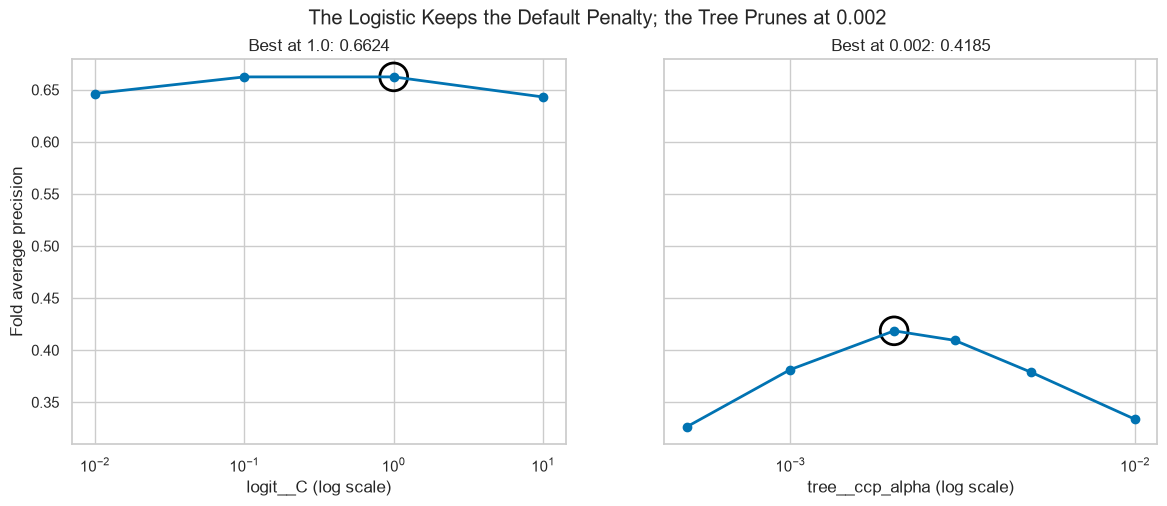

In [47]:
# fold average precision against each dial, on a log axis, the chosen value ringed
fig, (left, right) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, search, setting in [(left, c_search, "logit__C"), (right, post_search, "tree__ccp_alpha")]:
    values = [params[setting] for params in search.cv_results_["params"]]
    ax.plot(values, search.cv_results_["mean_test_score"], marker="o", linewidth=2)
    ax.scatter(search.best_params_[setting], search.best_score_, s=400, facecolor="none", edgecolor="black", linewidth=2)
    ax.set_xscale("log")
    ax.set(xlabel=setting + " (log scale)", title=f"Best at {search.best_params_[setting]}: {search.best_score_:.4f}")
left.set_ylabel("Fold average precision")
fig.suptitle("The Logistic Keeps the Default Penalty; the Tree Prunes at 0.002")
plt.show()

`C` of 0.1, 1.0 and 10.0 all score within 0.02 of each other; 0.1 and 1.0 tie at 0.6624 to four decimals and the search keeps 1.0, the default: shrinkage has nothing more to give.

`ccp_alpha` 0.002 scores 0.4185 with 43 leaves, below the pre-pruned tree's 0.5254.

**Each dial is chosen on the folds: the logistic keeps its default penalty, and pre-pruning beats post-pruning here.**

In [48]:
check("Q15 best C", q15_c, "c4cac4d1653a", places=2)

Q15 best C: correct


## Thresholds for a Recall of 0.70

Day 8 set its threshold on validation rows.
Here the folds do that job: `cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")` fits the model five times and gives each training company the probability from the fit that did not see it, an **out-of-fold** probability.

![Out-of-fold probabilities. The 4,680 training companies in five folds of 936. Five fits: each is fitted on four folds and gives a probability to each of the 936 companies in the fold it did not see. Put back together, the 4,680 training companies each have one out-of-fold probability, and Day 8's rule reads the threshold for a recall of 0.70 from them; the test rows never take part.](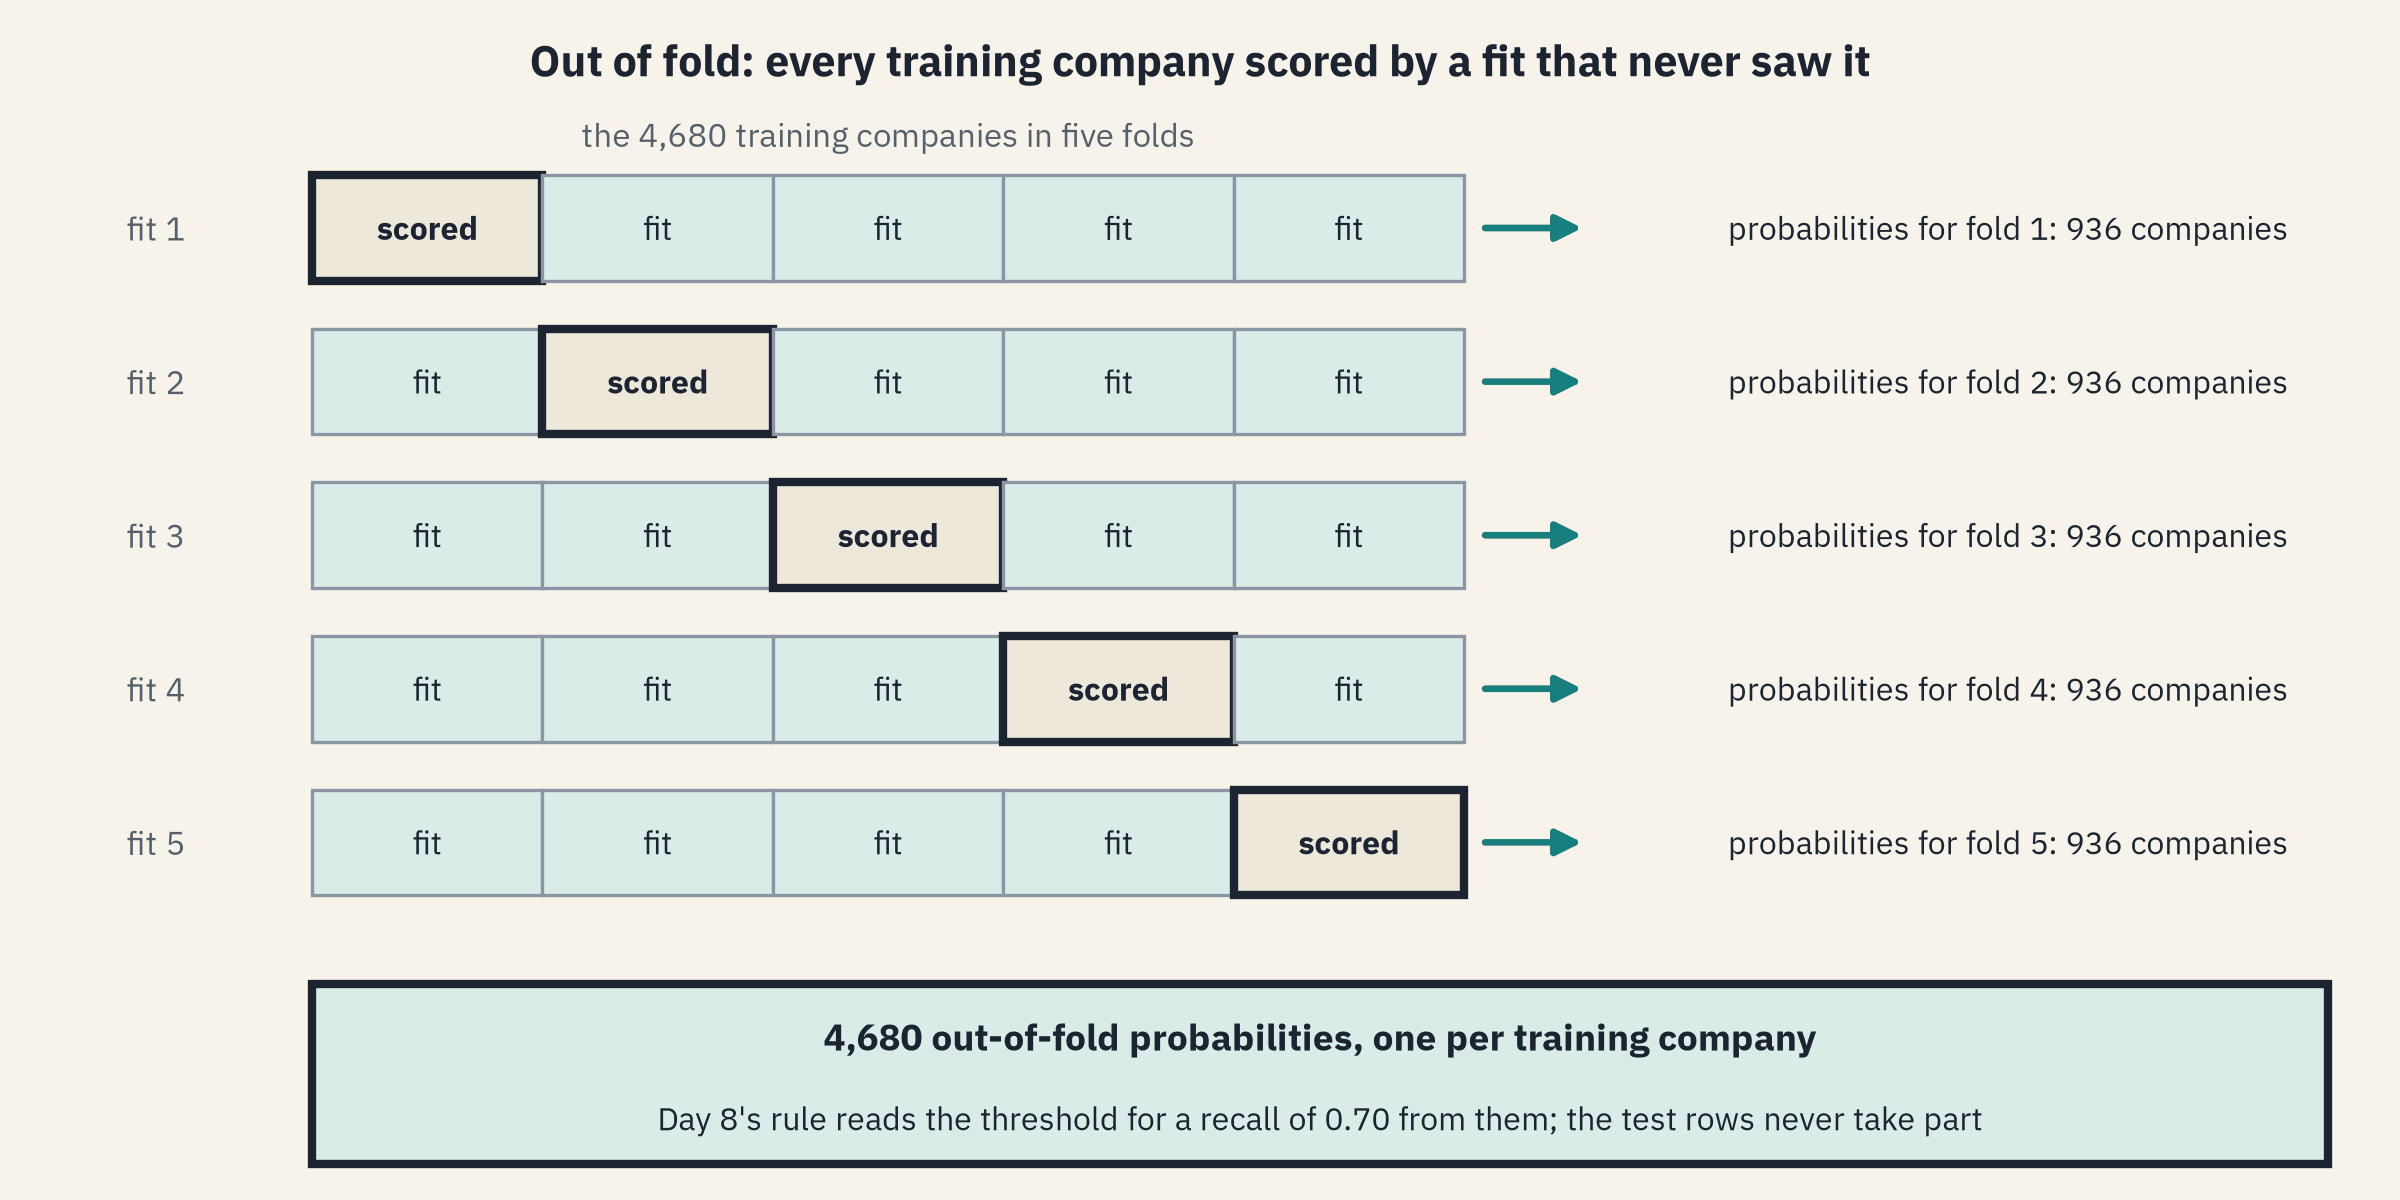)

Q. Put the three models in a dictionary `models` under the keys `"logistic"`, `"pre-pruned tree"` and `"post-pruned tree"`. Keep each one's out-of-fold probabilities in a dictionary `out_of_fold` and its threshold for a recall of 0.70 by Day 8's rule in `thresholds_70`. Store the thresholds in `q16_logistic`, `q16_pre` and `q16_post` (4 decimals).

Q. Draw the three out-of-fold precision-recall curves on one chart, recall 0.70 dashed and each model's threshold as a dot.

In [49]:
# the three models by name
models = {"logistic": logistic, "pre-pruned tree": pre_pruned, "post-pruned tree": post_pruned}

# each training company's out-of-fold probability, then Day 8's rule for a recall of 0.70
out_of_fold, thresholds_70 = {}, {}
for name, model in models.items():
    out_of_fold[name] = cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba")[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_train, out_of_fold[name])
    thresholds_70[name] = thresholds[recall[:-1] >= 0.70].max()
q16_logistic, q16_pre, q16_post = thresholds_70["logistic"], thresholds_70["pre-pruned tree"], thresholds_70["post-pruned tree"]

In [50]:
# each threshold, the training companies it flags out of fold, and the recall and precision of those flags
summary = pd.DataFrame({"threshold": thresholds_70})
summary["flagged"] = [(out_of_fold[name] >= thresholds_70[name]).sum() for name in models]
summary["recall"] = [recall_score(y_train, out_of_fold[name] >= thresholds_70[name]) for name in models]
summary["precision"] = [precision_score(y_train, out_of_fold[name] >= thresholds_70[name]) for name in models]
summary

,threshold,flagged,recall,precision
logistic,0.7134,481,0.7025,0.4761
pre-pruned tree,0.4880,710,0.7025,0.3225
post-pruned tree,0.0383,866,0.7025,0.2644


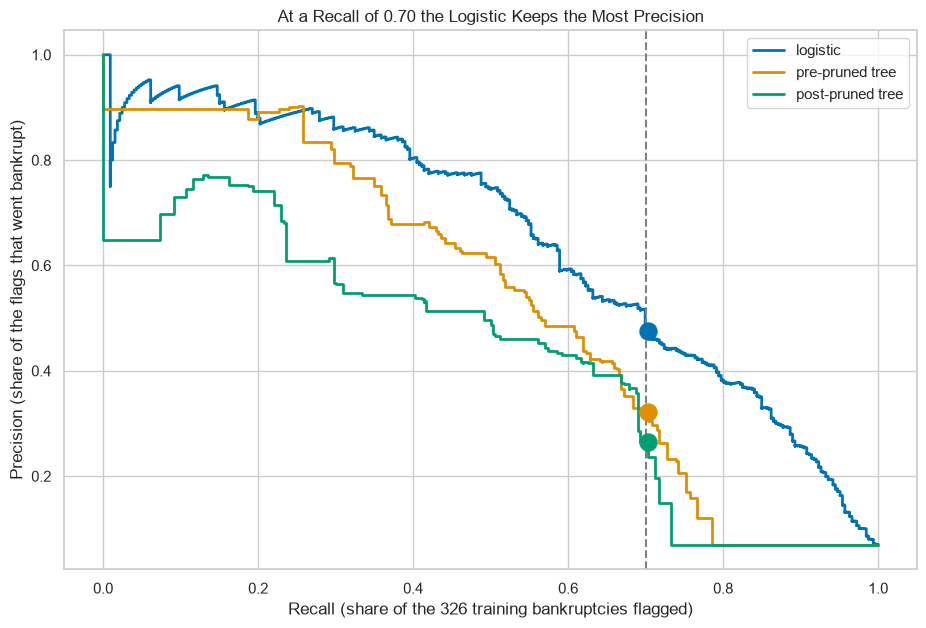

In [51]:
# each model's out-of-fold precision-recall curve, a dot where its threshold for 0.70 lands
plt.figure(figsize=(11, 7))
for number, name in enumerate(models):
    precision, recall, thresholds = precision_recall_curve(y_train, out_of_fold[name])
    plt.plot(recall, precision, drawstyle="steps-post", linewidth=2, color=f"C{number}", label=name)
    plt.scatter(summary.loc[name, "recall"], summary.loc[name, "precision"], s=150, color=f"C{number}", zorder=3)
plt.axvline(0.70, color="gray", linestyle="--")
plt.xlabel("Recall (share of the 326 training bankruptcies flagged)")
plt.ylabel("Precision (share of the flags that went bankrupt)")
plt.title("At a Recall of 0.70 the Logistic Keeps the Most Precision")
plt.legend(loc="upper right")
plt.show()

To catch 70 percent of the 326 training bankruptcies, the logistic flags 481 companies, the pre-pruned tree 710 and the post-pruned tree 866.

The post-pruned tree's threshold is 0.0383, close to zero: only a very low bar reaches 0.70 with its leaves.

At recall 0.70 the logistic's flags are 47.6 percent bankrupt, the pre-pruned tree's 32.3 and the post-pruned tree's 26.4.

The logistic's curve sits above both trees almost everywhere.

In [52]:
check("Q16 logistic threshold", q16_logistic, "e2e6e9d8ca50", places=4)
check("Q16 pre-pruned threshold", q16_pre, "8765d4564dbe", places=4)
check("Q16 post-pruned threshold", q16_post, "66bfa7576242", places=4)

Q16 logistic threshold: correct
Q16 pre-pruned threshold: correct
Q16 post-pruned threshold: correct


# Final Model Selection

The criterion was set before any model was fitted: fold average precision first.

**Predict 4**

Q. Score each model on the training rows it was fitted on. Which one has the highest average precision there, and what is it? Write down a name and a number.

## Judged on Their Own Rows

Q. Fit `logistic` on the training rows (the searches already refitted the trees), and score all three there with the scoring function, each at its threshold. Set each training-row average precision beside its fold score in a table `gap_table`. Store the key of the model highest on the training rows in `q17_model` and its score in `q17_ap` (4 decimals).

In [53]:
# the logistic fitted on every training row, then all three scored on those rows, each at its threshold
logistic.fit(X_train, y_train)
train_comp = pd.concat([model_performance_classification(models[name], X_train, y_train, thresholds_70[name]).T for name in models], axis=1)
train_comp.columns = list(models)
train_comp

,logistic,pre-pruned tree,post-pruned tree
Average precision,0.7206,0.7908,0.5969
ROC AUC,0.9595,0.9766,0.9655
Accuracy,0.9368,0.9137,0.9002
Recall,0.7638,0.9540,0.9969
Precision,0.5321,0.4443,0.4109
F1,0.6272,0.6062,0.5819


In [54]:
# average precision on the rows each model was fitted on, beside the folds it did not see
fold_ap = pd.Series({"logistic": q10_ap, "pre-pruned tree": q13_ap, "post-pruned tree": q14_ap})
gap_table = pd.DataFrame({"training rows": train_comp.loc["Average precision"], "folds": fold_ap})
q17_model, q17_ap = gap_table["training rows"].idxmax(), gap_table["training rows"].max()
gap_table

,training rows,folds
logistic,0.7206,0.6624
pre-pruned tree,0.7908,0.5254
post-pruned tree,0.5969,0.4185


On the rows it was fitted on, the pre-pruned tree leads with 0.7908, against 0.7206 for the logistic and 0.5969 for the post-pruned tree.

On the folds the order is the logistic first, 0.6624, then the trees at 0.5254 and 0.4185.

In [55]:
check("Q17 model with the highest training-row score", q17_model, "fa9e2d519e4c")
check("Q17 its training-row average precision", q17_ap, "70959b8c257a", places=4)

Q17 model with the highest training-row score: correct
Q17 its training-row average precision: correct


## The Choice

Q. Which model goes forward, by the criterion set before any model was fitted? Store its key in `models` in `q18_choice`, and write one reason a line.

In [56]:
# the criterion's three readings side by side: the fold score, the flags it takes for 0.70, the gap from training rows
q18_choice = "logistic"
pd.DataFrame({"fold AP": fold_ap, "flagged for 0.70": summary["flagged"], "training AP minus fold AP": gap_table["training rows"] - gap_table["folds"]})

,fold AP,flagged for 0.70,training AP minus fold AP
logistic,0.6624,481,0.0582
pre-pruned tree,0.5254,710,0.2653
post-pruned tree,0.4185,866,0.1784


The logistic has the highest fold average precision, 0.6624, the criterion itself.

It flags the fewest training companies for a recall of 0.70: 481, against 710 and 866.

Its training-row score sits closest to its fold score, a gap of 0.0582.

**Judged on the rows they were fitted on, the pre-pruned tree would have been chosen; on the folds, the logistic regression goes forward.**

In [57]:
check("Q18 the choice", q18_choice, "ad44a3ef2bb1")

Q18 the choice: correct


# The Test Rows, Opened Once

**Predict 5**

Out of fold, the logistic's threshold of 0.7134 catches 70.25 percent of the 326 training bankruptcies.

Q. How many of the 82 test bankruptcies does it flag?

## The Test Table

Q. Score the three models on the test rows in one table, `test_comp`, each at its threshold, and keep each model's test flags in a dictionary `test_flags`. Store the number of test bankruptcies the logistic flags in `q19_caught` and its test average precision in `q19_ap` (4 decimals).

Q. Draw the three test confusion matrices side by side in Day 7's four colours.

A **bump chart** ranks the models on each measure, first at the top, and joins each model's ranks with a line.

Q. Draw a bump chart of the models' ranks on training-row and fold average precision and on the test table's average precision, ROC AUC, recall and precision.

In [58]:
# the test rows, opened once: each model at the threshold chosen out of fold
test_comp = pd.concat([model_performance_classification(models[name], X_test, y_test, thresholds_70[name]).T for name in models], axis=1)
test_comp.columns = list(models)

# each model's flags on the test rows, and the logistic's catches among the 82 bankruptcies
test_flags = {name: models[name].predict_proba(X_test)[:, 1] >= thresholds_70[name] for name in models}
q19_caught, q19_ap = (test_flags["logistic"] & (y_test == 1)).sum(), test_comp.loc["Average precision", "logistic"]
print("The logistic flags", q19_caught, "of", (y_test == 1).sum(), "test bankruptcies")
test_comp

The logistic flags 61 of 82 test bankruptcies


,logistic,pre-pruned tree,post-pruned tree
Average precision,0.6761,0.6197,0.4829
ROC AUC,0.9307,0.8347,0.8558
Accuracy,0.9274,0.8966,0.8769
Recall,0.7439,0.7561,0.8171
Precision,0.4880,0.3804,0.3418
F1,0.5894,0.5061,0.4820


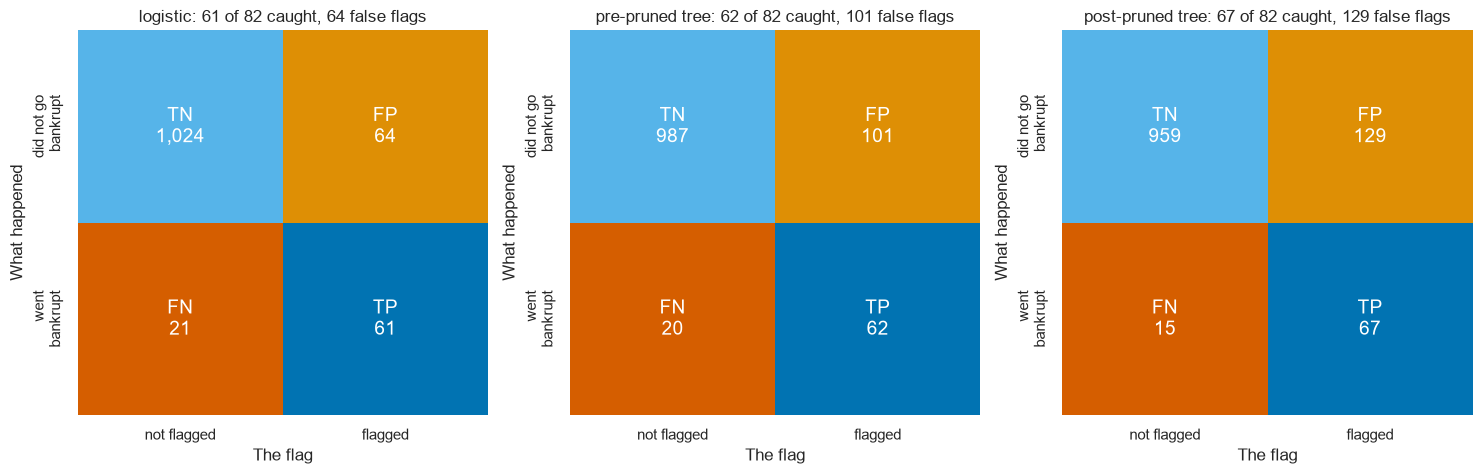

In [59]:
# the three test matrices, each cell in Day 7's colour with its name and count
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, models):
    tn, fp, fn, tp = confusion_matrix(y_test, test_flags[name]).ravel()
    labels = [[f"TN\n{tn:,}", f"FP\n{fp:,}"], [f"FN\n{fn:,}", f"TP\n{tp:,}"]]
    sns.heatmap([[0, 1], [2, 3]], cmap=list(CELL_COLOURS.values()), annot=labels, fmt="", cbar=False, ax=ax, annot_kws={"size": 14},
                xticklabels=["not flagged", "flagged"], yticklabels=["did not go\nbankrupt", "went\nbankrupt"])
    ax.set(xlabel="The flag", ylabel="What happened", title=f"{name}: {tp} of 82 caught, {fp} false flags")
plt.show()

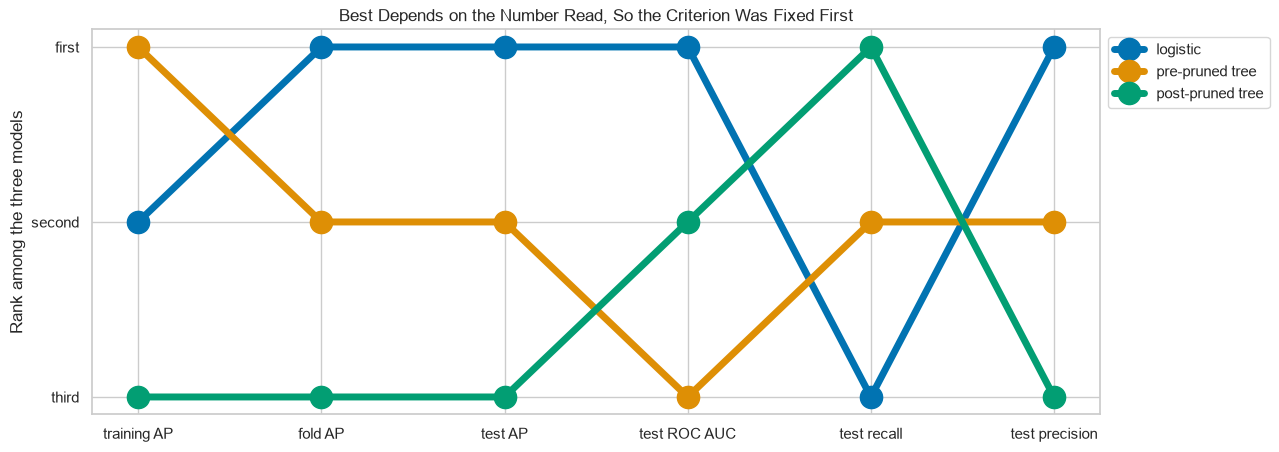

In [60]:
# six measures, each model ranked on each (1 = the highest), then each model's ranks joined
measures = pd.DataFrame({"training AP": gap_table["training rows"], "fold AP": gap_table["folds"], "test AP": test_comp.loc["Average precision"],
                         "test ROC AUC": test_comp.loc["ROC AUC"], "test recall": test_comp.loc["Recall"], "test precision": test_comp.loc["Precision"]})
ranks = measures.rank(ascending=False)
plt.figure(figsize=(13, 5))
for name in ranks.index:
    plt.plot(ranks.columns, ranks.loc[name], marker="o", markersize=16, linewidth=5, label=name)
plt.gca().invert_yaxis()
plt.yticks([1, 2, 3], ["first", "second", "third"])
plt.ylabel("Rank among the three models")
plt.title("Best Depends on the Number Read, So the Criterion Was Fixed First")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

The logistic scores 0.6761 in average precision and 0.9307 in ROC AUC on the test rows, close to its 0.6624 and 0.9281 on the folds.

At its threshold it catches 61 of the 82 bankruptcies, a recall of 0.7439, and 48.8 percent of its flags went bankrupt.

The trees catch one and six more bankruptcies than the logistic, 62 and 67, for 101 and 129 false flags against its 64.

The logistic is first on every measure but two: the pre-pruned tree leads on the rows it was fitted on, and the post-pruned tree on test recall.

Read the wrong row and any of the three looks best, which is why the criterion came before the results.

In [61]:
check("Q19 test bankruptcies flagged", q19_caught, "0ed5a337397e", places=0)
check("Q19 test average precision", q19_ap, "018f83cc6d60", places=4)

Q19 test bankruptcies flagged: correct
Q19 test average precision: correct


## Which Bankruptcies Each Model Catches

Q. For each of the 82 test bankruptcies, note which models flag it, in a table `caught` with one column per model. Store how many all three flag in `q20_all` and how many none flags in `q20_none`.

An **UpSet chart** counts overlapping groups: one bar per pattern, and under each bar a dot for every model in the pattern.

Q. Draw an UpSet chart of the patterns in `caught`.

In [62]:
# for each test bankruptcy, which models flag it, then how often each pattern occurs
went_test = (y_test == 1).to_numpy()
caught = pd.DataFrame({name: flags[went_test] for name, flags in test_flags.items()})
q20_all, q20_none = caught.all(axis=1).sum(), (~caught.any(axis=1)).sum()
patterns = caught.value_counts()
patterns

logistic  pre-pruned tree  post-pruned tree
True      True             True                51
False     True             True                11
          False            False                9
True      False            False                6
                           True                 4
False     False            True                 1
Name: count, dtype: int64

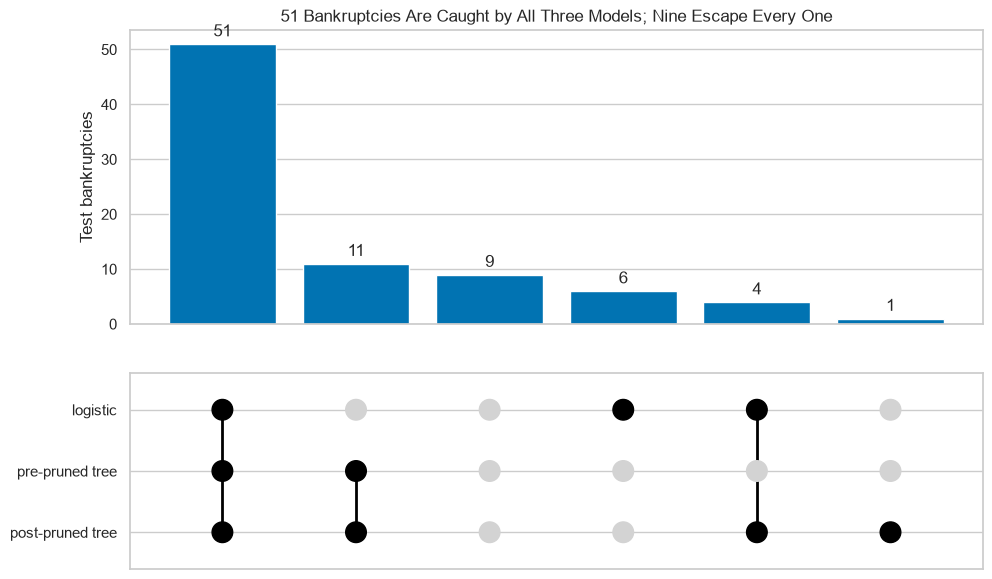

In [63]:
# one bar per pattern, and under it the models in the pattern as dark dots joined by a line
fig, (top, bottom) = plt.subplots(2, 1, figsize=(11, 7), sharex=True, height_ratios=[3, 2])
bars = top.bar(range(len(patterns)), patterns.to_numpy(), color="C0")
top.bar_label(bars, padding=3)
top.set(ylabel="Test bankruptcies", title="51 Bankruptcies Are Caught by All Three Models; Nine Escape Every One")
for column, pattern in enumerate(patterns.index):
    rows = [row for row, flagged in enumerate(pattern) if flagged]
    bottom.plot([column] * len(rows), rows, color="black", linewidth=2)
    bottom.scatter([column] * 3, [0, 1, 2], s=220, color=["black" if flagged else "lightgray" for flagged in pattern], zorder=3)
bottom.set_yticks([0, 1, 2], list(caught.columns))
bottom.set_ylim(2.6, -0.6)
bottom.set_xticks([])
plt.show()

51 of the 82 are caught by all three models and 9 by none.

11 are caught by both trees and not the logistic, and 6 by the logistic alone.

**The numbers held on companies nobody chose with, and nine bankruptcies escape every model.**

In [64]:
check("Q20 caught by all three", q20_all, "e2ffe8520eb9", places=0)
check("Q20 caught by none", q20_none, "edd66b199bc3", places=0)

Q20 caught by all three: correct
Q20 caught by none: correct


# Where the Model Fails

## What It Leans On

Q. Name the 112 columns with `logistic["impute"].get_feature_names_out()`. Take the fitted logistic's ten largest coefficients by size and the pre-pruned tree's ten largest importances, as Series `top_coefficients` and `top_importances`. How many columns are in both? Store it in `q21_common`.

Q. Draw the two top tens as lollipops side by side, the coefficients coloured by sign.

In [65]:
# the 112 column names after the imputer: the 64 features, then a missing indicator for each feature with a gap
names = logistic["impute"].get_feature_names_out()
coefficients = pd.Series(logistic["logit"].coef_[0], index=names)
importances = pd.Series(pre_pruned["tree"].feature_importances_, index=pre_pruned["impute"].get_feature_names_out())

# the ten largest of each, and the columns they share
top_coefficients = coefficients[coefficients.abs().nlargest(10).index]
top_importances = importances.nlargest(10)
q21_common = len(set(top_coefficients.index) & set(top_importances.index))
print(len(names), "columns;", q21_common, "in both top tens")

112 columns; 0 in both top tens


In [66]:
# the two top tens side by side
pd.DataFrame({"logistic": top_coefficients.index, "coefficient": top_coefficients.to_numpy(),
              "tree": top_importances.index, "importance": top_importances.to_numpy()})

,logistic,coefficient,tree,importance
0,Attr33,3.7253,Attr39,0.3495
1,Attr32,2.4732,missingindicator_Attr27,0.1165
2,Attr63,-1.7692,missingindicator_Attr21,0.0856
3,Attr62,1.7557,Attr34,0.0614
4,Attr8,1.5738,Attr29,0.0489
5,Attr22,-1.4848,Attr21,0.0336
6,missingindicator_Attr32,1.2789,Attr46,0.0273
7,Attr23,-1.2754,Attr55,0.0259
8,Attr49,1.2448,Attr4,0.0233
9,Attr52,-1.1737,Attr41,0.0211


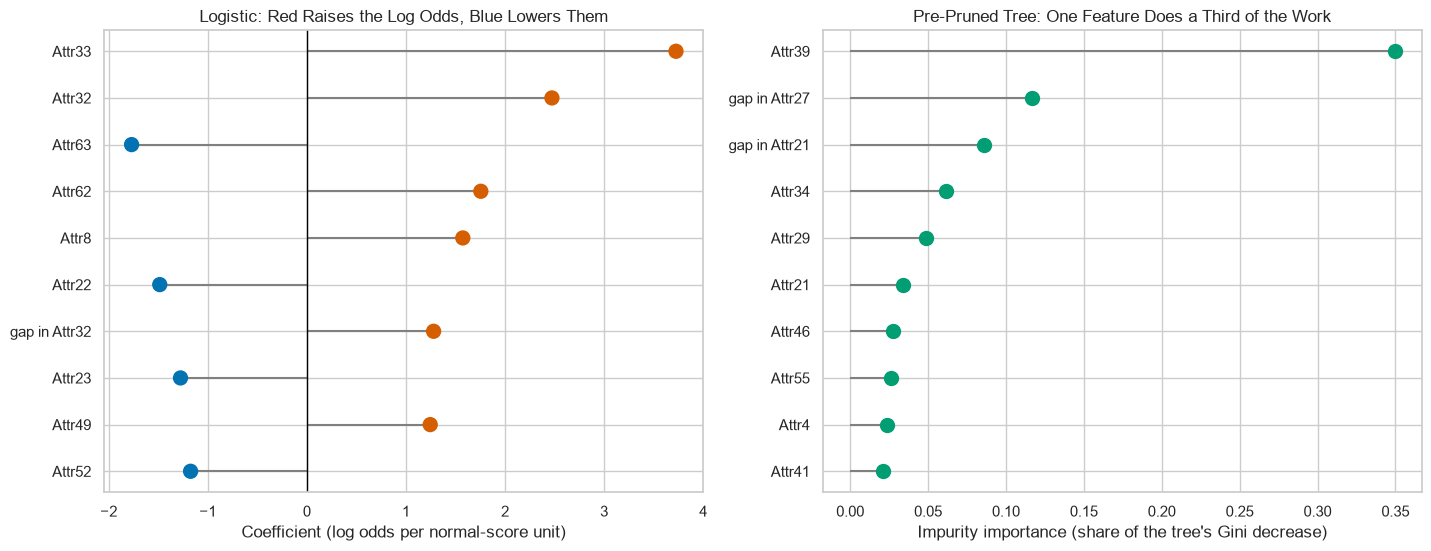

In [67]:
# shorter labels: a missing indicator written as "gap in" and its feature
coefficient_labels = [name.replace("missingindicator_", "gap in ") for name in top_coefficients.index]
importance_labels = [name.replace("missingindicator_", "gap in ") for name in top_importances.index]

# the logistic's ten largest coefficients and the tree's ten largest importances, side by side
fig, (left, right) = plt.subplots(1, 2, figsize=(17, 6))
left.hlines(coefficient_labels, 0, top_coefficients, color="gray")
left.scatter(top_coefficients, coefficient_labels, s=100, color=np.where(top_coefficients > 0, "C3", "C0"), zorder=3)
left.axvline(0, color="black", linewidth=1)
left.invert_yaxis()
left.set(xlabel="Coefficient (log odds per normal-score unit)", title="Logistic: Red Raises the Log Odds, Blue Lowers Them")
right.hlines(importance_labels, 0, top_importances, color="gray")
right.scatter(top_importances, importance_labels, s=100, color="C2", zorder=3)
right.invert_yaxis()
right.set(xlabel="Impurity importance (share of the tree's Gini decrease)", title="Pre-Pruned Tree: One Feature Does a Third of the Work")
plt.show()

In [68]:
# two features the logistic weighs in opposite directions, after the imputer and the quantile transform
scored = pd.DataFrame(logistic["quantile"].transform(logistic["impute"].transform(X_train)), columns=names)
print("Correlation of Attr33 and Attr63 in normal scores:", round(scored["Attr33"].corr(scored["Attr63"]), 3))

# the pre-pruned tree's first question and the two under it: max_depth=1 cuts the printout below them
print(export_text(pre_pruned["tree"], feature_names=list(names), max_depth=1, decimals=4))

Correlation of Attr33 and Attr63 in normal scores: 0.861
|--- Attr39 <= -0.0066
|   |--- Attr55 <= 867.9750
|   |   |--- truncated branch of depth 7
|   |--- Attr55 >  867.9750
|   |   |--- truncated branch of depth 7
|--- Attr39 >  -0.0066
|   |--- missingindicator_Attr27 <= 0.5000
|   |   |--- truncated branch of depth 7
|   |--- missingindicator_Attr27 >  0.5000
|   |   |--- truncated branch of depth 5



No column is in both top tens: the two models lean on different columns.

`Attr33` (+3.73) and `Attr63` (-1.77) both divide by short-term liabilities and correlate at 0.861 in normal scores: Day 3's near-copies pulling against each other, so the pair is read together, never one alone.

The tree asks about `Attr39` first and gives it 0.3495 of its importance; its next two columns are the gaps in `Attr27` and `Attr21`.

A gap is in the logistic's top ten too: the empty cells the overview found carry weight in both models.

All of this is association in this file, not cause.

In [69]:
check("Q21 columns in both top tens", q21_common, "405250f71bc2", places=0)

Q21 columns in both top tens: correct


## The Misses

Q. Which test bankruptcies does the logistic miss at its threshold? Store how many in `q22_missed`, and how many of them still show a positive `Attr39` in `q22_positive`.

In [70]:
# the logistic's test flags by row, then the bankruptcies it misses and the ones it catches
logistic_flag = pd.Series(test_flags["logistic"], index=X_test.index)
missed = X_test[(y_test == 1) & ~logistic_flag]
caught_rows = X_test[(y_test == 1) & logistic_flag]
q22_missed, q22_positive = len(missed), (missed["Attr39"] > 0).sum()
print(q22_missed, "missed;", q22_positive, "of them with Attr39 above 0")
print("Median Attr39, missed:", round(missed["Attr39"].median(), 4), " caught:", round(caught_rows["Attr39"].median(), 4))

21 missed; 12 of them with Attr39 above 0
Median Attr39, missed: 0.0175  caught: -0.1293


In [71]:
# the clusters the missed bankruptcies fall in, with PCA and K-means as fitted on the training rows
missed_clusters = pd.Series(kmeans.predict(pca_pipe.transform(missed)[:, :2])).map(renumber)
print("Missed bankruptcies by cluster:", missed_clusters.value_counts().sort_index().to_dict())

Missed bankruptcies by cluster: {0: 5, 1: 5, 2: 4, 3: 7}


21 bankruptcies are missed, and 12 of them still showed a profit on sales: their median `Attr39` is 0.0175, against -0.1293 for the 61 caught.

14 of the 21 sit outside cluster 3, the corner where most bankruptcies were.

The threshold stays where the folds set it: moving it now would choose on the test rows.

In [72]:
check("Q22 missed", q22_missed, "8cd4bde8507f", places=0)
check("Q22 missed with a positive Attr39", q22_positive, "96d187df201b", places=0)

Q22 missed: correct
Q22 missed with a positive Attr39: correct


# Insights and Conclusion

## The Description

Q. Write `description`, one string of a few sentences: what the chosen model separates and how well on the test rows, where it is wrong, what the data cannot support, and what was not tested. Then run the cell under it.

In [73]:
# the description, as one string
description = (
    "On the 1,170 test rows the logistic regression ranks the companies that went bankrupt with average precision 0.6761 and ROC AUC 0.9307. "
    "At the threshold chosen out of fold it flags 61 of the 82 bankruptcies, with 64 false flags. "
    "It misses 21, and 12 of them still showed a profit on sales: it is weakest where the ratios do not mark the company. "
    "The file is one country's companies, anonymised, with the bankrupt and the operating ones from different years and no dates, so order in time was never tested. "
    "Nothing here tested calibration, another period, or the cost of an error, and the output describes this file, not any company's credit."
)
print(description)

On the 1,170 test rows the logistic regression ranks the companies that went bankrupt with average precision 0.6761 and ROC AUC 0.9307. At the threshold chosen out of fold it flags 61 of the 82 bankruptcies, with 64 false flags. It misses 21, and 12 of them still showed a profit on sales: it is weakest where the ratios do not mark the company. The file is one country's companies, anonymised, with the bankrupt and the operating ones from different years and no dates, so order in time was never tested. Nothing here tested calibration, another period, or the cost of an error, and the output describes this file, not any company's credit.


In [74]:
# a reminder, not a proof: words that would turn a description into a view on a company
WATCH = ["forecast", "will go bankrupt", "will default", "cheap", "rich", "signal", "recommend", "should"]  # words this description never uses
found = [word for word in WATCH if word in str(description).lower()]
print("Words from the list in the description:", found)

Words from the list in the description: []


**A model describes the file it was fitted on.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Run a whole classification job on a real file, every choice made on training rows.
* Fill gaps inside a pipeline with `SimpleImputer` and its missing indicators.
* Read a file without its label with PCA and K-means.
* Choose settings with `GridSearchCV` on a pipeline, and a threshold from out-of-fold probabilities.
* Say what a model leans on and where it fails.

## Exercises

`check()` from Setting Up marks each answer.

### Exercise 1

**A Recall Target of 0.80**

Q. Find the logistic's out-of-fold threshold for a recall of 0.80 by Day 8's rule, and the training companies it flags. Store them in `ex1_threshold` (4 decimals) and `ex1_flagged`.

In [75]:
# Day 8's rule on the logistic's out-of-fold probabilities, for a recall of 0.80
precision, recall, thresholds = precision_recall_curve(y_train, out_of_fold["logistic"])
ex1_threshold = thresholds[recall[:-1] >= 0.80].max()
ex1_flagged = (out_of_fold["logistic"] >= ex1_threshold).sum()
print(round(ex1_threshold, 4), " Flagged:", ex1_flagged, " Precision:", round(precision_score(y_train, out_of_fold["logistic"] >= ex1_threshold), 4))

0.5307  Flagged: 682  Precision: 0.3827


Asking for 0.80 lowers the threshold from 0.7134 to 0.5307 and the flags rise from 481 to 682; fewer than four in ten of them went bankrupt.

In [76]:
check("Exercise 1 threshold", ex1_threshold, "32ffc66163a4", places=4)
check("Exercise 1 flagged", ex1_flagged, "48a5e6472744", places=0)

Exercise 1 threshold: correct
Exercise 1 flagged: correct


### Exercise 2

**PCA Inside the Pipeline**

Q. Put `PCA(n_components=20, random_state=SEED)` between the quantile transform and the logistic regression, and score the pipeline on the folds. Store its mean average precision in `ex2_ap` (4 decimals).

In [77]:
# the logistic pipeline with 20 principal components in place of the 112 columns
with_pca = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                     ("quantile", QuantileTransformer(output_distribution="normal", random_state=SEED)),
                     ("pca", PCA(n_components=20, random_state=SEED)),
                     ("logit", LogisticRegression(solver="newton-cholesky", tol=1e-8, class_weight="balanced"))])
ex2_ap = cross_validate(with_pca, X_train, y_train, cv=folds, scoring="average_precision")["test_score"].mean()
print("Fold average precision with 20 components:", round(ex2_ap, 4))

Fold average precision with 20 components: 0.6322


0.6322 against 0.6624: the 20 directions with the most variance are not the 20 that carry the most about the outcome.

In [78]:
check("Exercise 2 fold average precision", ex2_ap, "1a0651c6df50", places=4)

Exercise 2 fold average precision: correct


### Exercise 3: AI check

**Medians From Where?**

You asked an AI assistant for a function that drops the copies, fills every gap with the training rows' median, and splits 80/20.
This came back.
It runs, and its comments sound careful.
Test it, then find the one bug.
`.statistics_` holds the medians an imputer learned at `fit`.

In [79]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def prepare_with_medians(rows):
    # drop the copies, fill every gap with the training rows' median, then split 80/20 with the seed
    rows = rows.drop_duplicates()
    imputer = SimpleImputer(strategy="median").fit(rows[FEATURES])
    filled = pd.DataFrame(imputer.transform(rows[FEATURES]), columns=FEATURES, index=rows.index)
    X_tr, X_te, y_tr, y_te = train_test_split(filled, rows[TARGET], test_size=0.2, stratify=rows[TARGET], random_state=SEED)
    return X_tr, X_te, y_tr, y_te, imputer

In [80]:
# the test: the imputer's 64 medians must be the training rows' own (empty cells skipped)
ai_train, ai_test, ai_y_train, ai_y_test, ai_imputer = prepare_with_medians(bankrupt)
own = bankrupt.loc[ai_train.index, FEATURES].median()
differing = (~np.isclose(ai_imputer.statistics_, own)).sum()
assert differing == 0, f"{differing} of the 64 medians are not the training rows' own"

AssertionError: 63 of the 64 medians are not the training rows' own

Q. Fix the function: split first, then learn the medians from the training rows only. Store the number of medians that differ from the training rows' own after the fix in `ex3_differing`.

In [81]:
# the fix, a demonstration of the rule a pipeline keeps for us: split first, then learn the medians from the training rows only
def prepare_with_medians(rows):
    rows = rows.drop_duplicates()
    X_tr, X_te, y_tr, y_te = train_test_split(rows[FEATURES], rows[TARGET], test_size=0.2, stratify=rows[TARGET], random_state=SEED)
    imputer = SimpleImputer(strategy="median").fit(X_tr)
    filled_train = pd.DataFrame(imputer.transform(X_tr), columns=FEATURES, index=X_tr.index)
    filled_test = pd.DataFrame(imputer.transform(X_te), columns=FEATURES, index=X_te.index)
    return filled_train, filled_test, y_tr, y_te, imputer

fixed_train, fixed_test, fixed_y_train, fixed_y_test, fixed_imputer = prepare_with_medians(bankrupt)
ex3_differing = (~np.isclose(fixed_imputer.statistics_, bankrupt.loc[fixed_train.index, FEATURES].median())).sum()
print(ex3_differing, "of the 64 medians differ from the training rows' own")

0 of the 64 medians differ from the training rows' own


The assistant's imputer learned its medians from all 5,850 rows, the test rows among them, and only then split: 63 of the 64 medians are not the training rows' own.

Nothing in its output looks wrong; only a test of what the fitted step learned, and from which rows, finds it.

A pipeline fitted on the training rows keeps this rule without anyone having to remember it.

In [82]:
check("Exercise 3 medians differing after the fix", ex3_differing, "17e99f1802e2", places=0)

Exercise 3 medians differing after the fix: correct


## Congratulations!

You ran the whole course on one real file, and the work was yours.
You found gaps that say something, copies, and values in the millions, and handled each inside a pipeline.
You chose every setting and a threshold on the folds alone, opened the test rows once, and the numbers held.
Course 5 grows forests and boosting from a single tree, and these 4,680 training rows come back.

[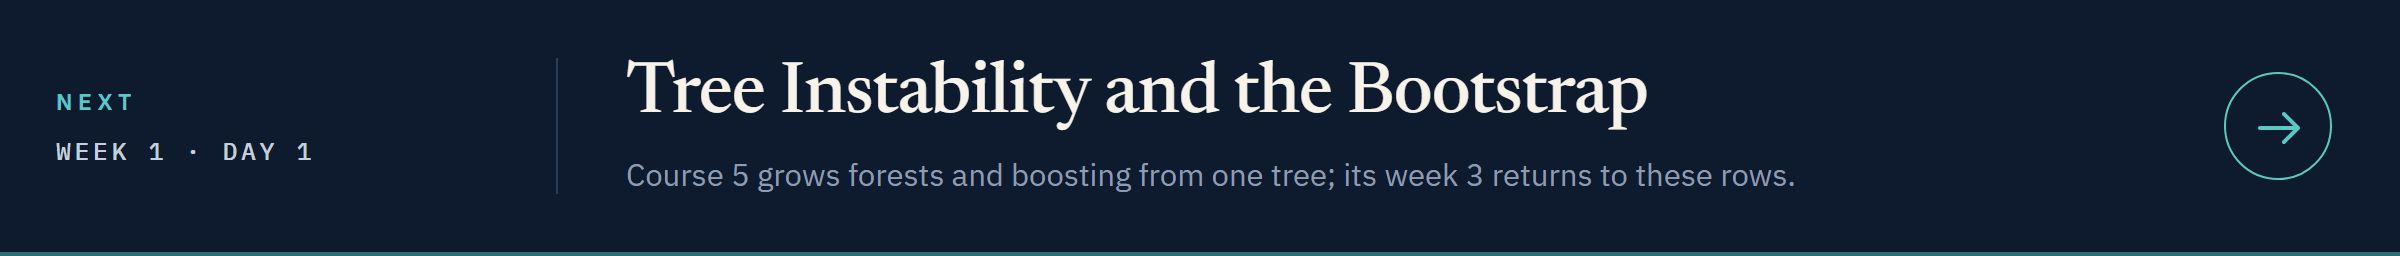](../../../course05_advanced_ml/week1/day1/01_tree_instability_and_the_bootstrap.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week1/day1/01_tree_instability_and_the_bootstrap.ipynb)